<img src="../docs/logo_voltride_clair.png" alt="VoltRide Motors" width="150">

# VoltRide Africa — Analyse stratégique avant l'ouverture de 20 stations (S1 2027)

**Rôle :** Data Analyst — mandat confié par le comité de direction
**Période :** 1er mai → 31 octobre 2026 (6 mois) · **Source :** `data/raw/voltride_dataset_senior.csv` (6 390 lignes brutes)

### Question centrale
> *Où et comment investir pour que les 20 nouvelles stations créent de la valeur, alors que le CA est irrégulier, que les remboursements et annulations pèsent, et que le marketing coûte cher ?*

### Plan du notebook
| # | Section | Livrable |
|---|---|---|
| 1 | Audit & compréhension des données | Résumé d'audit (`docs/audit_qualite.md`) |
| 2 | Data cleaning | `df_clean` + journal de nettoyage |
| 3 | Feature engineering | CA, marge, profit, CLV… |
| 4 | Analyses (performance, services, villes, marketing, clients) | Réponses aux 5 questions stratégiques |
| 5 | Bonus senior | Segments, remises, point mort d'une station |
| 6 | Recommandations & conclusion | 5 recommandations chiffrées |

### Conventions de calcul (à lire avant les chiffres)
* **Chiffre d'affaires (CA)** = quantité × prix × (1 − remise) pour les transactions **non annulées** (définition de l'énoncé). Il inclut donc les ventes ensuite remboursées.
* **CA net** = CA hors transactions remboursées. **Profit net réel** = profit après remboursements (le CA remboursé est rendu au client, le coût du service reste engagé).
* **Profit net** (définition de l'énoncé) = marge brute − coût marketing. Une transaction annulée n'a ni CA ni coût de service, mais son coût marketing est dépensé.
* **Taux d'annulation** = annulées / toutes les transactions. **Taux de remboursement** = remboursées / transactions non annulées.
* **ROI marketing** = (CA − coût marketing) / coût marketing (formule de l'énoncé). Le *ROI sur marge* = (marge brute − marketing) / marketing est plus exigeant et sert de contre-test.
* Montants en **FCFA**.

## 0. Configuration

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from voltride.cleaning import load_raw, clean, parse_date, map_service, map_ville, NON_RENSEIGNE
from voltride.features import add_features
from voltride.analysis import (kpis, group_table, monthly, client_table, pareto, station_table, breakeven,
                               VERT, ANTHRACITE, GRIS, ROUGE, ORANGE, PALETTE_CAT)

warnings.filterwarnings("ignore")
pio.renderers.default = "notebook_connected"
pio.templates.default = "plotly_white"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette=PALETTE_CAT)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
pd.options.display.float_format = lambda x: f"{x:,.2f}"
pd.options.display.max_columns = 40
pd.options.display.width = 200

def M(x):   # millions de FCFA
    return f"{x/1e6:,.2f} M".replace(",", " ")
def pct(x, n=1):
    return f"{x*100:.{n}f} %".replace(".", ",")
def millions(x, pos=None):
    return f"{x/1e6:.0f} M"
def save(fig, name):
    fig.savefig(FIG / name, dpi=160, bbox_inches="tight", facecolor="white")
print("Configuration OK - racine du projet :", ROOT)

Configuration OK - racine du projet : C:\Users\Ange\Desktop\DATA ANALYST\7. CLAUDE IA\Claude IA\Ressources\Jour 3- R- SQL-Python\PROJET VOLTRIDE


# 1. Audit & compréhension des données

Objectif : mesurer précisément l'état des données **avant** toute correction, pour que chaque traitement du §2 soit justifié par un constat.

In [2]:
raw = load_raw(ROOT / "data" / "raw" / "voltride_dataset_senior.csv")
print(f"{raw.shape[0]:,} lignes x {raw.shape[1]} colonnes".replace(",", " "))
display(raw.head(8))

6 390 lignes x 18 colonnes


,id_transaction,id_client,date_transaction,ville,pays,type_service,type_client,canal_acquisition,station,type_batterie,quantite,prix_unitaire_fcfa,remise_pct,cout_unitaire_fcfa,cout_marketing_fcfa,mode_paiement,statut,note_client
0,TRX004044,CLI01263,2026-10-13,Douala,Cameroun,Accessoires & maintenance,Livreur,TikTok Ads,ST-DOU-01,N/A,1,9150,0.0,5750.0,1877.0,Espèces à la station,Terminée,NaN
1,TRX005348,CLI00030,2026-07-25,ABIDJAN,Côte d'Ivoire,Abonnement mensuel,Chauffeur moto-taxi,TikTok Ads,ST-ABI-06,Longue autonomie 60V,3,27200,0.0,18700.0,2154.0,Espèces à la station,Terminée,3.0
2,TRX001643,CLI00124,28/06/2026,Lomé,Togo,Location journalière,Chauffeur moto-taxi,TikTok Ads,ST-LOM-06,Standard 48V,5,6150,0.0,4400.0,1516.0,Mobile Money (Orange/MTN/Moov/Wave),Terminée,2.0
3,TRX005612,CLI00964,09/10/2026,Lomé,Togo,Swap batterie,Livreur,Facebook Ads,ST-LOM-03,Standard 48V,3,1500,0.0,900.0,1924.0,Espèces à la station,Terminée,2.0
4,TRX000998,CLI00646,27/07/2026,Douala,Cameroun,Swap batterie,Chauffeur moto-taxi,Parrainage,ST-DOU-06,Standard 48V,1,1550,0.0,850.0,611.0,Mobile Money (Orange/MTN/Moov/Wave),Terminée,5.0
5,TRX004722,CLI01077,2026-09-24,Abidjan,Côte d'Ivoire,Location journalière,Particulier,TikTok Ads,ST-ABI-07,Standard 48V,0,6150,0.0,4450.0,1922.0,Mobile Money (Orange/MTN/Moov/Wave),Remboursée,NaN
6,TRX005864,CLI00282,08-07-26,Douala,Cameroun,Swap batterie,Particulier,Meta Ads (Facebook/Instagram),ST-DOU-03,Longue autonomie 60V,3,1600,0.0,900.0,1596.0,Espèces à la station,Terminée,5.0
7,TRX005380,CLI00503,2026-10-22,Lomé,Togo,Location journalière,Particulier,affichage & stations,ST-LOM-05,Longue autonomie 60V,5,6000,0.0,4250.0,837.0,especes,Remboursée,2.0


### 1.1 Structure et types

In [3]:
# Le fichier est lu en texte : le typage réel est inféré ci-dessous pour détecter les colonnes mal typées.
num_cols = ["quantite", "prix_unitaire_fcfa", "remise_pct", "cout_unitaire_fcfa", "cout_marketing_fcfa", "note_client"]
types = pd.DataFrame({
    "type_lu": raw.dtypes.astype(str),
    "type_attendu": ["texte (id)", "texte (id)", "date", "catégorie", "catégorie", "catégorie", "catégorie", "catégorie",
                     "texte (code)", "catégorie", "entier", "numérique", "numérique %", "numérique", "numérique", "catégorie",
                     "catégorie", "numérique (1-5)"],
    "valeurs_distinctes": raw.nunique(),
})
display(types)
print("Mémoire :", f"{raw.memory_usage(deep=True).sum()/1e6:.1f} Mo")

,type_lu,type_attendu,valeurs_distinctes
id_transaction,str,texte (id),6200
id_client,str,texte (id),1159
date_transaction,str,date,861
ville,str,catégorie,26
pays,str,catégorie,5
type_service,str,catégorie,21
type_client,str,catégorie,4
canal_acquisition,str,catégorie,25
station,str,texte (code),40
type_batterie,str,catégorie,3


Mémoire : 2.0 Mo


**Constat :** tout est lu en texte. `date_transaction` doit devenir une vraie date, et les colonnes numériques sont à contrôler (valeurs aberrantes). Les **variables catégorielles ont trop de valeurs distinctes** (ex. `ville` : 26 variantes pour 5 villes) — signe de saisies non normalisées.

### 1.2 Valeurs manquantes

,manquants,pct
note_client,1325,20.74
cout_marketing_fcfa,204,3.19
canal_acquisition,116,1.82
mode_paiement,105,1.64
ville,77,1.21
station,73,1.14
cout_unitaire_fcfa,69,1.08
type_client,57,0.89
type_service,34,0.53
date_transaction,12,0.19


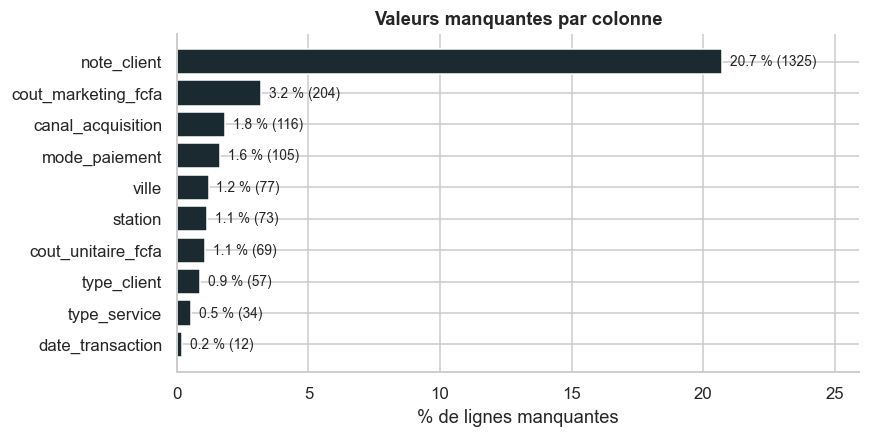

In [4]:
manq = (raw.isna().sum().to_frame("manquants").assign(pct=lambda x: x.manquants / len(raw) * 100)
        .sort_values("manquants", ascending=False))
display(manq[manq.manquants > 0])

fig, ax = plt.subplots(figsize=(8, 4))
mm = manq[manq.manquants > 0].sort_values("pct")
ax.barh(mm.index, mm.pct, color=ANTHRACITE)
for i, (v, n) in enumerate(zip(mm.pct, mm.manquants)):
    ax.text(v + 0.3, i, f"{v:.1f} % ({n})", va="center", fontsize=9)
ax.set_xlabel("% de lignes manquantes"); ax.set_title("Valeurs manquantes par colonne")
ax.set_xlim(0, mm.pct.max() * 1.25)
save(fig, "01_audit_manquants.png"); plt.show()

**Constat :** `note_client` (20,7 %) est manquante surtout pour les transactions **annulées** (pas d'expérience à noter) : ce n'est pas une erreur, on **ne l'impute pas**. `type_batterie` vaut `N/A` pour les accessoires : c'est une valeur légitime (pas de batterie), conservée comme « Sans objet ». Les manquants **à traiter** sont : `cout_marketing_fcfa` (204), `canal_acquisition` (116), `mode_paiement` (105), `ville` (77), `station` (73), `cout_unitaire_fcfa` (69), `type_client` (57), `type_service` (34), `date_transaction` (12).

### 1.3 Doublons

In [5]:
dup_exact = raw.duplicated().sum()
dup_id = raw["id_transaction"].duplicated().sum()
norm = raw.assign(id_client=raw.id_client.str.upper(), id_transaction=raw.id_transaction.str.upper())
dup_norm = norm.duplicated().sum()
print(f"Doublons exacts (brut)                         : {dup_exact}")
print(f"id_transaction répétés                         : {dup_id}")
print(f"Doublons exacts après normalisation des id     : {dup_norm}")
print("Exemple : même transaction, id_client écrit 'CLI00309' puis 'cli00309'")
display(raw[raw.id_transaction == "TRX000080"][["id_transaction", "id_client", "date_transaction", "ville", "type_service", "quantite", "statut"]])

Doublons exacts (brut)                         : 183
id_transaction répétés                         : 190
Doublons exacts après normalisation des id     : 190
Exemple : même transaction, id_client écrit 'CLI00309' puis 'cli00309'


,id_transaction,id_client,date_transaction,ville,type_service,quantite,statut
3285,TRX000080,CLI00309,2026-07-05,Abidjan,Location journalière,3,Annulée
5190,TRX000080,cli00309,2026-07-05,Abidjan,Location journalière,3,Annulée


**Constat :** 183 doublons exacts + 7 doublons masqués par une **casse différente de `id_client`** (`CLI00309` / `cli00309`) = **190 lignes en trop** (3,0 %). Les ignorer gonflerait le CA.

### 1.4 Incohérences de format et de libellé

In [6]:
# --- dates : motifs rencontrés
motif = raw.date_transaction.fillna("<vide>").str.replace(r"[0-9]", "9", regex=True).str.replace(r"[a-zéû\.]+", "mmm", regex=True)
fmt = motif.value_counts().rename("lignes").to_frame()
fmt["exemple"] = [raw.date_transaction[motif == m].iloc[0] if m != "<vide>" else "" for m in fmt.index]
fmt["lecture retenue"] = fmt.index.map({
    "9999-99-99": "AAAA-MM-JJ (ISO)", "99/99/9999": "JJ/MM/AAAA (jamais de 2e bloc > 12)",
    "99-99-99": "JJ-MM-AA", "99-99-9999": "MM-JJ-AAAA (le 2e bloc dépasse 12 -> impossible en JJ-MM)",
    "9999/99/99": "AAAA/MM/JJ", "9 mmm 9999": "JJ mois AAAA (français)", "99 mmm 9999": "JJ mois AAAA (français)", "<vide>": "manquante"}).fillna("")
display(fmt)

# --- libellés : variantes par colonne catégorielle
cat_cols = ["ville", "pays", "type_service", "type_client", "canal_acquisition", "mode_paiement", "statut"]
var = pd.DataFrame({"variantes_brutes": [raw[c].nunique() for c in cat_cols],
                    "valeurs_attendues": [5, 5, 4, 4, 6, 3, 3]}, index=cat_cols)
display(var)
print("Exemples pour 'statut' :", sorted(raw.statut.unique()))

,lignes,exemple,lecture retenue
date_transaction,,,
9999-99-99,3478,2026-10-13,AAAA-MM-JJ (ISO)
99/99/9999,1635,28/06/2026,JJ/MM/AAAA (jamais de 2e bloc > 12)
99-99-99,333,08-07-26,JJ-MM-AA
99-99-9999,306,09-30-2026,MM-JJ-AAAA (le 2e bloc dépasse 12 -> impossibl...
99 mmm 9999,300,26 mai 2026,JJ mois AAAA (français)
9999/99/99,194,2026/05/01,AAAA/MM/JJ
9 mmm 9999,132,8 sept 2026,JJ mois AAAA (français)
<mmm>,12,NaN,


,variantes_brutes,valeurs_attendues
ville,26,5
pays,5,5
type_service,21,4
type_client,4,4
canal_acquisition,25,6
mode_paiement,9,3
statut,18,3


Exemples pour 'statut' : ['ANNULEE', 'Annulé', 'Annulée', 'Cancelled', 'Completed', 'REMBOURSEE', 'Refunded', 'Remboursé', 'Remboursée', 'TERMINEE', 'Terminé', 'Terminée', 'annulee', 'annulée ', 'remboursee', 'remboursée ', 'terminee', 'terminée']


**Constat :** **6 formats de date** coexistent. Deux sont ambigus : `JJ/MM/AAAA` (le premier bloc dépasse 12 dans 1 019 cas et le second jamais → c'est bien jour/mois) et `MM-JJ-AAAA` (ex. `10-18-2026`). Les libellés sont pollués par la casse, les espaces, les fautes (« Abidjian », « Doaula »), l'anglais (« Completed », « Refunded ») et les abréviations (« Abo mensuel », « Loc. journalière »).

### 1.5 Valeurs aberrantes

,colonne,anomalie,lignes
0,quantite,Quantité nulle,61
1,quantite,Quantité négative,6
2,quantite,"Quantité irréaliste (> 10, max normal = 5)",5
3,prix_unitaire_fcfa,Prix négatif,5
4,prix_unitaire_fcfa,Prix nul,11
5,prix_unitaire_fcfa,Prix x10 (ratio 8-12 vs médiane du service),47
6,prix_unitaire_fcfa,Prix x100 (ratio 80-120),6
7,remise_pct,Remise négative,71
8,remise_pct,Remise > 100 %,8
9,cout_marketing_fcfa,"Coût marketing aberrant (> 5 000 ; P99,5 = 2 817)",12


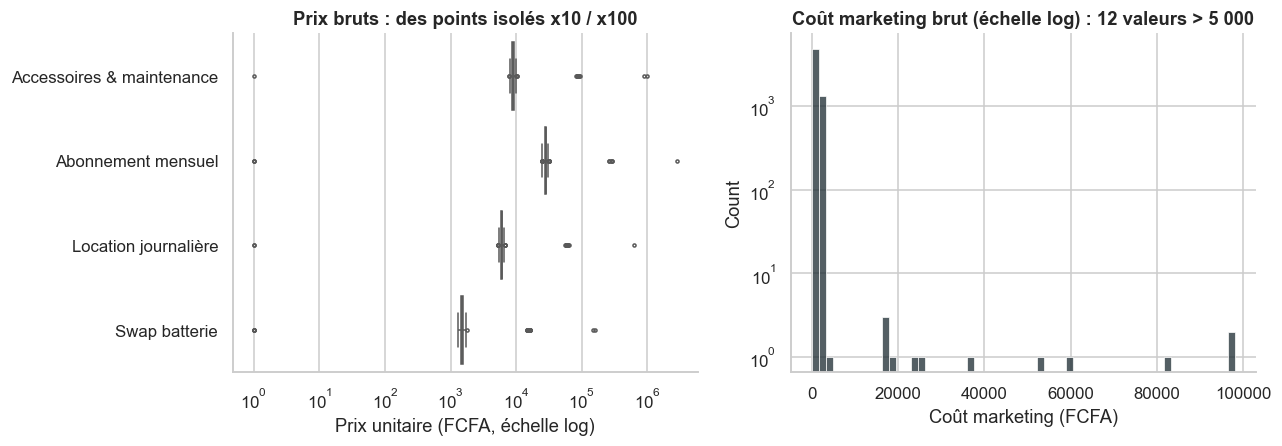

In [7]:
n = raw.copy()
for c in num_cols:
    n[c] = pd.to_numeric(n[c], errors="coerce")
n["service"] = n.type_service.map(map_service)
ref = n.assign(p=n.prix_unitaire_fcfa.abs()).query("p > 0").groupby("service").p.median()
ratio = n.prix_unitaire_fcfa.abs() / n.service.map(ref)

anomalies = pd.DataFrame([
    ("quantite", "Quantité nulle", (n.quantite == 0).sum()),
    ("quantite", "Quantité négative", (n.quantite < 0).sum()),
    ("quantite", "Quantité irréaliste (> 10, max normal = 5)", (n.quantite > 10).sum()),
    ("prix_unitaire_fcfa", "Prix négatif", (n.prix_unitaire_fcfa < 0).sum()),
    ("prix_unitaire_fcfa", "Prix nul", (n.prix_unitaire_fcfa == 0).sum()),
    ("prix_unitaire_fcfa", "Prix x10 (ratio 8-12 vs médiane du service)", ratio.between(8, 12).sum()),
    ("prix_unitaire_fcfa", "Prix x100 (ratio 80-120)", ratio.between(80, 120).sum()),
    ("remise_pct", "Remise négative", (n.remise_pct < 0).sum()),
    ("remise_pct", "Remise > 100 %", (n.remise_pct > 100).sum()),
    ("cout_marketing_fcfa", "Coût marketing aberrant (> 5 000 ; P99,5 = 2 817)", (n.cout_marketing_fcfa > 5000).sum()),
    ("cout_unitaire_fcfa", "Coût unitaire manquant", n.cout_unitaire_fcfa.isna().sum()),
    ("cout_marketing_fcfa", "Coût marketing manquant", n.cout_marketing_fcfa.isna().sum()),
], columns=["colonne", "anomalie", "lignes"])
display(anomalies)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bx = n[n.service.notna()].assign(prix=lambda t: t.prix_unitaire_fcfa.abs().clip(lower=1))
sns.boxplot(data=bx, y="service", x="prix", ax=axes[0], color=GRIS, fliersize=2)
axes[0].set_xscale("log"); axes[0].set_xlabel("Prix unitaire (FCFA, échelle log)"); axes[0].set_ylabel("")
axes[0].set_title("Prix bruts : des points isolés x10 / x100")
sns.histplot(n.cout_marketing_fcfa.dropna(), bins=60, ax=axes[1], color=ANTHRACITE)
axes[1].set_yscale("log"); axes[1].set_xlabel("Coût marketing (FCFA)"); axes[1].set_title("Coût marketing brut (échelle log) : 12 valeurs > 5 000")
save(fig, "02_audit_aberrants.png"); plt.show()

**Constat :** les prix d'un service sont très stables (ex. swap ≈ 1 500 FCFA) : les valeurs x10 / x100 sont donc des **erreurs de saisie** reconnaissables et **corrigeables**, pas de vrais prix. Les remises réelles vont de 0 à 20 % ; les valeurs négatives ou > 100 % sont invalides.

### 1.6 Résumé d'audit

In [8]:
audit = pd.DataFrame([
    ("Doublons", "id_transaction / id_client", "190 lignes (3,0 %)", "Doublons exacts, dont 7 masqués par la casse de id_client", "Suppression"),
    ("Dates", "date_transaction", "2 803 lignes non ISO ; 12 vides ; ~13 impossibles", "6 formats ; certaines dates inexistantes", "Conversion + suppression des impossibles"),
    ("Villes", "ville", "916 variantes fautives ; 77 vides", "26 graphies pour 5 villes", "Correction + reconstitution via la station"),
    ("Services", "type_service", "1 010 libellés non standard ; 34 vides", "21 graphies pour 4 services", "Uniformisation + inférence par le coût"),
    ("Canaux / paiement", "canal_acquisition, mode_paiement", "765 / 607 non standard ou vides", "25 et 9 graphies", "Uniformisation, 'Non renseigné'"),
    ("Statuts", "statut", "956 lignes non standard", "18 graphies (FR/EN, casse, accents)", "Uniformisation en 3 statuts"),
    ("Quantités", "quantite", "61 nulles, 6 négatives, 5 irréalistes", "Erreurs de saisie", "Suppression / valeur absolue"),
    ("Prix", "prix_unitaire_fcfa", "~70 anormaux (négatifs, nuls, x10, x100)", "Écart net avec la médiane du service", "Correction par facteur ou médiane"),
    ("Remises", "remise_pct", "79 invalides (< 0 ou > 100 %)", "Remises réelles : 0-20 %", "Mise à 0 %"),
    ("Coûts", "cout_unitaire_fcfa, cout_marketing_fcfa", "69 + 204 manquants ; 12 marketing aberrants", "Valeurs absentes ou 20-40x la normale", "Médiane par service / par canal"),
    ("Satisfaction", "note_client", "1 325 vides (20,7 %)", "Surtout les annulations : normal", "Conservée telle quelle"),
], columns=["Thème", "Colonne(s)", "Volume", "Constat", "Traitement prévu"])
display(audit)

md_lines = ["# Audit qualité des données — VoltRide Africa", "",
            f"Fichier brut : {len(raw):,} lignes x {raw.shape[1]} colonnes (1er mai - 31 oct. 2026).".replace(",", " "), "",
            "| " + " | ".join(audit.columns) + " |", "|" + "---|" * len(audit.columns)]
md_lines += ["| " + " | ".join(str(v) for v in r) + " |" for r in audit.itertuples(index=False)]
md_lines += ["", "Le détail chiffré de chaque correction figure dans `data/processed/journal_nettoyage.csv`."]
(ROOT / "docs" / "audit_qualite.md").write_text("\n".join(md_lines), encoding="utf-8")

,Thème,Colonne(s),Volume,Constat,Traitement prévu
0,Doublons,id_transaction / id_client,"190 lignes (3,0 %)","Doublons exacts, dont 7 masqués par la casse d...",Suppression
1,Dates,date_transaction,2 803 lignes non ISO ; 12 vides ; ~13 impossibles,6 formats ; certaines dates inexistantes,Conversion + suppression des impossibles
2,Villes,ville,916 variantes fautives ; 77 vides,26 graphies pour 5 villes,Correction + reconstitution via la station
3,Services,type_service,1 010 libellés non standard ; 34 vides,21 graphies pour 4 services,Uniformisation + inférence par le coût
4,Canaux / paiement,"canal_acquisition, mode_paiement",765 / 607 non standard ou vides,25 et 9 graphies,"Uniformisation, 'Non renseigné'"
5,Statuts,statut,956 lignes non standard,"18 graphies (FR/EN, casse, accents)",Uniformisation en 3 statuts
6,Quantités,quantite,"61 nulles, 6 négatives, 5 irréalistes",Erreurs de saisie,Suppression / valeur absolue
7,Prix,prix_unitaire_fcfa,"~70 anormaux (négatifs, nuls, x10, x100)",Écart net avec la médiane du service,Correction par facteur ou médiane
8,Remises,remise_pct,79 invalides (< 0 ou > 100 %),Remises réelles : 0-20 %,Mise à 0 %
9,Coûts,"cout_unitaire_fcfa, cout_marketing_fcfa",69 + 204 manquants ; 12 marketing aberrants,Valeurs absentes ou 20-40x la normale,Médiane par service / par canal


1768

In [9]:
# Part de lignes touchées (diagnostic global)
fmt_flags = pd.DataFrame({
    "date": ~raw.date_transaction.fillna("x").str.fullmatch(r"\d{4}-\d{2}-\d{2}"), "ville": ~raw.ville.isin(["Abidjan", "Dakar", "Douala", "Cotonou", "Lomé"]),
    "service": ~raw.type_service.isin(["Swap batterie", "Location journalière", "Abonnement mensuel", "Accessoires & maintenance"]),
    "canal": ~raw.canal_acquisition.isin(["Meta Ads (Facebook/Instagram)", "TikTok Ads", "Partenariat chauffeurs VTC", "Parrainage", "WhatsApp Business", "Affichage & stations"]),
    "paiement": ~raw.mode_paiement.isin(["Mobile Money (Orange/MTN/Moov/Wave)", "Espèces à la station", "Carte bancaire"]),
    "statut": ~raw.statut.isin(["Terminée", "Annulée", "Remboursée"]), "id_client": raw.id_client != raw.id_client.str.upper()})
val_flags = pd.DataFrame({
    "quantité": (n.quantite <= 0) | (n.quantite > 10), "prix": (n.prix_unitaire_fcfa <= 0) | ~ratio.between(0.5, 1.6),
    "remise": (n.remise_pct < 0) | (n.remise_pct > 100), "marketing": n.cout_marketing_fcfa.isna() | (n.cout_marketing_fcfa > 5000),
    "coût": n.cout_unitaire_fcfa.isna(), "doublon": raw.duplicated(), "station": raw.station.isna(), "type_client": raw.type_client.isna()})
print(f"Lignes avec au moins une incohérence de format/libellé : {fmt_flags.any(axis=1).mean():.0%}")
print(f"Lignes avec au moins une anomalie de valeur (manquant, aberrant, doublon) : {val_flags.any(axis=1).mean():.0%}")
print(f"Lignes avec au moins un problème : {pd.concat([fmt_flags, val_flags], axis=1).any(axis=1).mean():.0%}")

Lignes avec au moins une incohérence de format/libellé : 75%
Lignes avec au moins une anomalie de valeur (manquant, aberrant, doublon) : 13%
Lignes avec au moins un problème : 78%


**Verdict d'audit :** les données sont exploitables mais **pas fiables en l'état** : **78 % des lignes** présentent au moins une incohérence, mais l'essentiel est de **forme** (formats de date, libellés) et se corrige par règle ; **13 % des lignes** ont une anomalie de **valeur** (manquant, aberrant, doublon). Aucune anomalie n'est irrécupérable : seules **4,4 %** des lignes sont finalement supprimées.

# 2. Data cleaning

Principe : **chaque règle est codée une fois** dans `src/voltride/cleaning.py`, journalisée, et rejouable (`python scripts/run_cleaning.py`). On préfère corriger quand la valeur correcte est déductible (format, référentiel, médiane du service), et supprimer quand elle ne l'est pas (date impossible, quantité 0).

In [10]:
df_clean, journal = clean(raw)
display(journal)
print(f"{len(raw):,} lignes brutes -> {len(df_clean):,} lignes propres ({len(raw)-len(df_clean)} retirées, {(len(raw)-len(df_clean))/len(raw):.1%})".replace(",", " "))

,regle,lignes_concernees,traitement
0,Doublons exacts (ids normalisés),190,"Suppression, 1re occurrence conservée"
1,id_transaction répété (contenu différent),0,"Suppression, 1re occurrence conservée"
2,Dates dans un format non ISO,2803,Conversion vers AAAA-MM-JJ
3,"Dates manquantes, impossibles ou hors période",25,Suppression (impossible de rattacher la ligne ...
4,"Statuts hétérogènes (casse, accents, anglais)",956,Uniformisation : Terminée / Annulée / Remboursée
5,"Villes mal orthographiées (casse, espaces, fau...",916,Correction par proximité de chaîne
6,Villes manquantes,75,Reconstituée depuis le code station (ST-XXX-NN)
7,Pays à reconstituer (encodage ou incohérence a...,0,Pays dérivé de la ville corrigée (référentiel)
8,Libellés de service hétérogènes,1010,Uniformisation vers les 4 lignes de service
9,Service manquant,33,Inféré par le coût unitaire le plus proche ; s...


6 390 lignes brutes -> 6 110 lignes propres (280 retirées  4.4%)


### Arbitrages assumés
| Sujet | Décision | Justification |
|---|---|---|
| Dates `JJ/MM/AAAA` vs `MM-JJ-AAAA` | Lecture déduite du contenu (bloc > 12) | Aucune ambiguïté résiduelle sur les formats avec tiret et AAAA |
| Dates impossibles / manquantes | Suppression (25 lignes) | Impossible de les rattacher à un mois |
| Prix x10 / x100 | Division par 10 / 100 | Le ratio à la médiane du service est quasi parfait |
| Remises invalides | 0 % | Non vérifiables ; hypothèse prudente (n'invente pas de remise) |
| Marketing manquant / aberrant | Médiane du canal | Le coût varie surtout selon le canal |
| Service manquant | Inféré par le coût unitaire le plus proche | Les 4 services ont des coûts très distincts (≈ 900 / 4 300 / 6 500 / 17 500) |
| Annulées | **Conservées** | Nécessaires pour le taux d'annulation |

In [11]:
# --- Contrôles de qualité post-nettoyage (le notebook échoue si une règle n'est pas respectée)
assert df_clean.id_transaction.is_unique
assert df_clean.date_transaction.between("2026-05-01", "2026-10-31").all()
assert set(df_clean.ville) == {"Abidjan", "Cotonou", "Dakar", "Douala", "Lomé"}
assert df_clean.type_service.nunique() == 4 and df_clean.statut.nunique() == 3
assert df_clean.quantite.between(1, 10).all()
assert df_clean.prix_unitaire_fcfa.gt(0).all() and df_clean.remise_pct.between(0, 100).all()
assert df_clean.cout_marketing_fcfa.between(0, 5000).all() and df_clean.cout_unitaire_fcfa.notna().all()
assert not df_clean.drop(columns="note_client").isna().any().any()
print("Tous les contrôles passent.")

avant_apres = pd.DataFrame({"avant": [raw[c].nunique() for c in cat_cols], "après": [df_clean[c].nunique() for c in cat_cols]}, index=cat_cols)
display(avant_apres)

Tous les contrôles passent.


,avant,après
ville,26,5
pays,5,5
type_service,21,4
type_client,4,5
canal_acquisition,25,7
mode_paiement,9,4
statut,18,3


# 3. Feature engineering

Les variables sont créées dans `src/voltride/features.py` (même code pour le notebook et le dashboard).

| Variable | Définition |
|---|---|
| `chiffre_affaires` | quantité × prix × (1 − remise), 0 si annulée |
| `marge_brute` | CA − quantité × coût unitaire |
| `profit_net` | marge brute − coût marketing |
| `ca_net`, `profit_net_reel` | idem, après retrait des ventes remboursées |
| `mois` | mois de la transaction |
| `indicateur_remboursement` | 1 si remboursée |
| `nombre_transactions_par_client` | nb de transactions non annulées du client |
| `valeur_vie_client` | profit net cumulé du client sur la période (CLV simplifiée) |

In [12]:
df = add_features(df_clean)
new_cols = ["chiffre_affaires", "marge_brute", "profit_net", "ca_net", "profit_net_reel", "mois_label",
            "indicateur_remboursement", "nombre_transactions_par_client", "valeur_vie_client", "frequence_client"]
display(df[["id_transaction", "type_service", "statut", "quantite", "prix_unitaire_fcfa", "remise_pct"] + new_cols].head(6))

# Contrôle de cohérence : recalcul indépendant du CA
ok = df[df.statut != "Annulée"]
recalc = (ok.quantite * ok.prix_unitaire_fcfa * (1 - ok.remise_pct / 100)).sum()
assert np.isclose(recalc, df.chiffre_affaires.sum()) and (df.loc[df.statut == "Annulée", "chiffre_affaires"] == 0).all()
print(f"CA recalculé indépendamment = CA du dataset = {M(recalc)} FCFA")
df.to_csv(ROOT / "data" / "processed" / "df_clean.csv", index=False, encoding="utf-8-sig")

,id_transaction,type_service,statut,quantite,prix_unitaire_fcfa,remise_pct,chiffre_affaires,marge_brute,profit_net,ca_net,profit_net_reel,mois_label,indicateur_remboursement,nombre_transactions_par_client,valeur_vie_client,frequence_client
0,TRX005758,Accessoires & maintenance,Terminée,1,8800,0.00,"8,800.00","2,900.00","2,284.00","8,800.00","2,284.00",2026-05,0,20,"80,664.00",Fidèle (6+)
1,TRX001649,Abonnement mensuel,Terminée,1,26700,10.00,"24,030.00","8,030.00","6,799.00","24,030.00","6,799.00",2026-05,0,2,"9,359.00",Occasionnel (1-2)
2,TRX000645,Accessoires & maintenance,Annulée,2,9200,0.00,0.00,0.00,"-2,322.00",0.00,"-2,322.00",2026-05,0,50,"155,187.00",Fidèle (6+)
3,TRX003930,Abonnement mensuel,Terminée,2,28350,0.00,"56,700.00","20,500.00","19,355.00","56,700.00","19,355.00",2026-05,0,96,"767,710.00",Fidèle (6+)
4,TRX002721,Location journalière,Terminée,3,6400,0.00,"19,200.00","7,050.00","5,588.00","19,200.00","5,588.00",2026-05,0,15,"58,066.00",Fidèle (6+)
5,TRX006146,Swap batterie,Terminée,4,1450,0.00,"5,800.00","2,200.00",196.00,"5,800.00",196.00,2026-05,0,208,"778,922.00",Fidèle (6+)


CA recalculé indépendamment = CA du dataset = 95.30 M FCFA


# 4. Analyses

## 4.1 Performance globale

,Valeur
Indicateur,
Transactions,6 110
Clients,1 098
CA total (hors annulées),95.30 M FCFA
CA net des remboursements,86.91 M FCFA
Marge brute,"30.91 M FCFA (32,4 % du CA)"
Coût marketing,6.72 M FCFA
Profit net estimé,24.19 M FCFA
Profit net réel (après remboursements),15.80 M FCFA
Panier moyen,17 287 FCFA


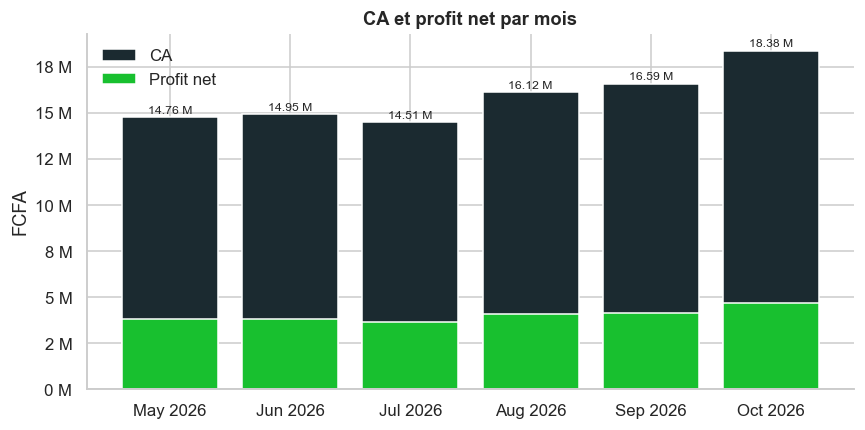

Lecture : CA oct. vs mai = 24,5 % ; mois le plus faible = Jul 2026 ; le profit net suit le CA (marge de profit stable ≈ 25,4 %).


In [13]:
k = kpis(df)
tab = pd.DataFrame({"Indicateur": ["Transactions", "Clients", "CA total (hors annulées)", "CA net des remboursements", "Marge brute",
                                   "Coût marketing", "Profit net estimé", "Profit net réel (après remboursements)", "Panier moyen",
                                   "Taux d'annulation", "Taux de remboursement"],
                    "Valeur": [f"{k['transactions']:,}".replace(",", " "), f"{k['clients']:,}".replace(",", " "), M(k['ca_total']) + " FCFA",
                               M(k['ca_net']) + " FCFA", M(k['marge_brute']) + f" FCFA ({pct(k['marge_pct'])} du CA)", M(k['marketing']) + " FCFA",
                               M(k['profit_net']) + " FCFA", M(k['profit_net_reel']) + " FCFA", f"{k['panier_moyen']:,.0f} FCFA".replace(",", " "),
                               pct(k['taux_annulation']), pct(k['taux_remboursement'])]})
display(tab.set_index("Indicateur"))

mo = monthly(df)
mo["label"] = mo.mois.dt.strftime("%b %Y")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(mo.label, mo.ca, color=ANTHRACITE, label="CA")
ax.bar(mo.label, mo.profit_net, color=VERT, label="Profit net")
for x, v in zip(mo.label, mo.ca):
    ax.text(x, v + 2e5, M(v), ha="center", fontsize=8)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(millions)); ax.set_ylabel("FCFA")
ax.set_title("CA et profit net par mois"); ax.legend(frameon=False)
save(fig, "03_ca_profit_mensuel.png"); plt.show()

fig = go.Figure()
fig.add_bar(x=mo.mois, y=mo.ca, name="CA", marker_color=ANTHRACITE)
fig.add_scatter(x=mo.mois, y=mo.annulation * 100, name="Taux d'annulation (%)", yaxis="y2", mode="lines+markers", line=dict(color=ROUGE))
fig.update_layout(title="Interactif - CA mensuel et taux d'annulation", yaxis2=dict(overlaying="y", side="right", title="%", range=[0, 15]),
                  height=380, legend=dict(orientation="h", y=-0.2))
fig.show()
croiss = mo.ca.iloc[-1] / mo.ca.iloc[0] - 1
print(f"Lecture : CA oct. vs mai = {pct(croiss)} ; mois le plus faible = {mo.loc[mo.ca.idxmin(), 'label']} ; "
      f"le profit net suit le CA (marge de profit stable ≈ {pct(df.profit_net.sum()/df.chiffre_affaires.sum())}).")

**Lecture business.**
* VoltRide a facturé **95,3 M FCFA** sur 6 mois pour **24,2 M FCFA de profit net estimé** (25 % du CA), mais **8,4 M FCFA de ventes sont ensuite remboursées** : le profit net réel tombe à **15,8 M FCFA**. **Les remboursements effacent un tiers du profit.**
* Le « CA irrégulier » vient surtout d'un **creux de juillet (−3 %)** suivi d'un rebond (+11 % en août, +11 % en octobre) ; la tendance est nettement haussière (**+24 % entre mai et octobre**).
* 1 transaction sur 10 est annulée (9,8 %) et 7,4 % des ventes finalisées sont remboursées : l'exécution est un levier de profit aussi important que la croissance.

## 4.2 Analyse par ligne de service

,transactions,ca,marge_pct,marketing,profit_net,profit_net_reel,panier_moyen,taux_annulation,taux_remboursement,roi_marketing,part_ca
type_service,,,,,,,,,,,
Abonnement mensuel,1110,"54,786,665.00",0.35,"1,199,150.50","18,170,764.50","14,416,324.50","53,923.88",0.08,0.07,44.69,0.57
Location journalière,1313,"20,223,490.00",0.25,"1,460,116.50","3,677,673.50","763,141.00","17,285.03",0.11,0.14,12.85,0.21
Accessoires & maintenance,703,"10,728,417.50",0.26,"785,157.50","1,970,710.00","580,277.50","17,388.03",0.12,0.14,12.66,0.11
Swap batterie,2984,"9,565,250.00",0.38,"3,270,615.00","375,285.00","44,892.50","3,529.61",0.09,0.03,1.92,0.10


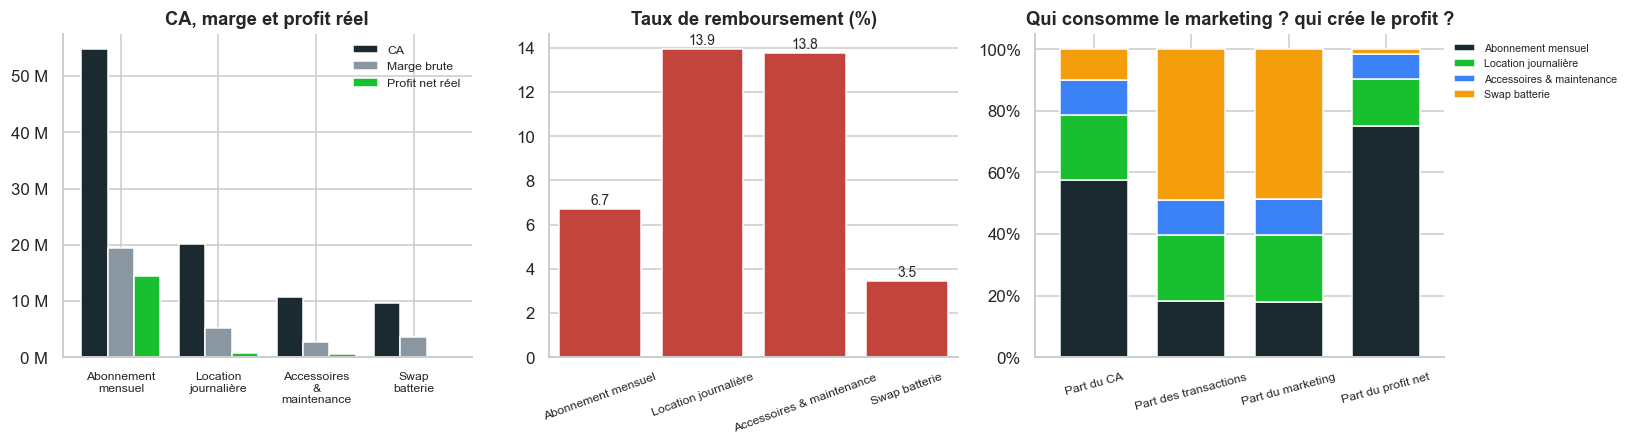

Lecture : le swap = 49% des transactions, 10 % du CA, mais 49% du marketing -> profit net = 375 k FCFA (1.6% du total).


In [14]:
sv = group_table(df, "type_service").sort_values("ca", ascending=False)
display(sv[["transactions", "ca", "marge_pct", "marketing", "profit_net", "profit_net_reel", "panier_moyen",
            "taux_annulation", "taux_remboursement", "roi_marketing", "part_ca"]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.arange(len(sv)); w = 0.27
axes[0].bar(x - w, sv.ca, w, color=ANTHRACITE, label="CA")
axes[0].bar(x, sv.marge_brute, w, color=GRIS, label="Marge brute")
axes[0].bar(x + w, sv.profit_net_reel, w, color=VERT, label="Profit net réel")
axes[0].set_xticks(x); axes[0].set_xticklabels([s.replace(" & ", "\n& ").replace(" ", "\n", 1) for s in sv.index], fontsize=8)
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(millions)); axes[0].legend(frameon=False, fontsize=8); axes[0].set_title("CA, marge et profit réel")
sns.barplot(x=sv.index, y=sv.taux_remboursement * 100, ax=axes[1], color=ROUGE)
axes[1].set_title("Taux de remboursement (%)"); axes[1].set_xlabel(""); axes[1].set_ylabel(""); axes[1].tick_params(axis="x", labelrotation=20, labelsize=8)
for i, v in enumerate(sv.taux_remboursement * 100): axes[1].text(i, v + 0.2, f"{v:.1f}", ha="center", fontsize=9)
part = pd.DataFrame({"Part du CA": sv.part_ca, "Part des transactions": sv.transactions / sv.transactions.sum(),
                     "Part du marketing": sv.marketing / sv.marketing.sum(), "Part du profit net": sv.profit_net / sv.profit_net.sum()}).T
part.plot(kind="bar", stacked=True, ax=axes[2], color=PALETTE_CAT[:4], width=0.7, legend=True)
axes[2].legend(fontsize=7, frameon=False, bbox_to_anchor=(1, 1)); axes[2].set_title("Qui consomme le marketing ? qui crée le profit ?")
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[2].tick_params(axis="x", labelrotation=15, labelsize=8)
plt.tight_layout(); save(fig, "04_services.png"); plt.show()

ms = monthly(df, "type_service")
fig = px.line(ms, x="mois", y="ca", color="type_service", markers=True, color_discrete_sequence=PALETTE_CAT,
              title="Interactif - Évolution mensuelle du CA par service", labels={"ca": "CA (FCFA)", "mois": "", "type_service": ""})
fig.update_layout(height=380, legend=dict(orientation="h", y=-0.2)); fig.show()

sw = sv.loc["Swap batterie"]
print(f"Lecture : le swap = {sv.loc['Swap batterie','transactions']/sv.transactions.sum():.0%} des transactions, {pct(sv.loc['Swap batterie','part_ca'],0)} du CA, "
      f"mais {sw.marketing/sv.marketing.sum():.0%} du marketing -> profit net = {sw.profit_net/1e3:,.0f} k FCFA ({sw.profit_net/sv.profit_net.sum():.1%} du total).")

**Lecture business.**
* **L'abonnement mensuel est le moteur** : 57 % du CA, **75 % du profit net**, 35 % de marge, remboursement modéré (6,7 %), ROI marketing de 45. C'est la ligne à protéger et à développer.
* **Le swap est un piège de rentabilité** : c'est la ligne la plus fréquente (49 % des transactions) avec la meilleure marge unitaire (38 %), mais le panier est de **3 500 FCFA** alors que le coût marketing alloué par transaction est quasiment le même pour tous les services (≈ 1 100 FCFA). Résultat : **49 % du budget marketing pour 1,6 % du profit** (profit réel ≈ 45 k FCFA). Le swap est une porte d'entrée, pas un centre de profit.
* **Location journalière et accessoires** ont des marges faibles (≈ 25 %) et surtout **~14 % de remboursements** : après remboursements, leur profit chute de **79 %** pour la location (3,68 M → 0,76 M) et de **71 %** pour les accessoires (1,97 M → 0,58 M).

**Réponse à la question stratégique — quelle ligne prioriser / optimiser ?**
1. **Prioriser l'abonnement** (porte d'entrée swap → abonnement, voir §4.5).
2. **Optimiser en urgence la location et les accessoires** : le levier n'est pas le prix mais la qualité (pannes, retards de livraison, batteries défectueuses → remboursements).
3. **Redéfinir l'économie du swap** : cesser de l'acquérir via les canaux chers (§4.4).

## 4.3 Analyse géographique

,transactions,ca,profit_net,profit_net_reel,profit_reel_pct_ca,taux_annulation,taux_remboursement,croissance_T2_vs_T1,panier_moyen
ville,,,,,,,,,
Abidjan,2172,"35,090,567.50","8,801,705.50","5,993,515.50",0.17,0.08,0.07,0.23,"17,519.01"
Dakar,1119,"17,475,295.00","4,616,418.00","3,572,023.00",0.20,0.08,0.06,0.02,"17,015.87"
Douala,1145,"16,726,092.50","4,215,763.50","2,278,891.00",0.14,0.15,0.09,-0.01,"17,279.02"
Lomé,932,"13,800,220.00","3,330,714.50","1,845,429.50",0.13,0.10,0.08,0.20,"16,370.37"
Cotonou,742,"12,211,647.50","3,229,831.50","2,114,776.50",0.17,0.09,0.07,0.38,"18,172.09"


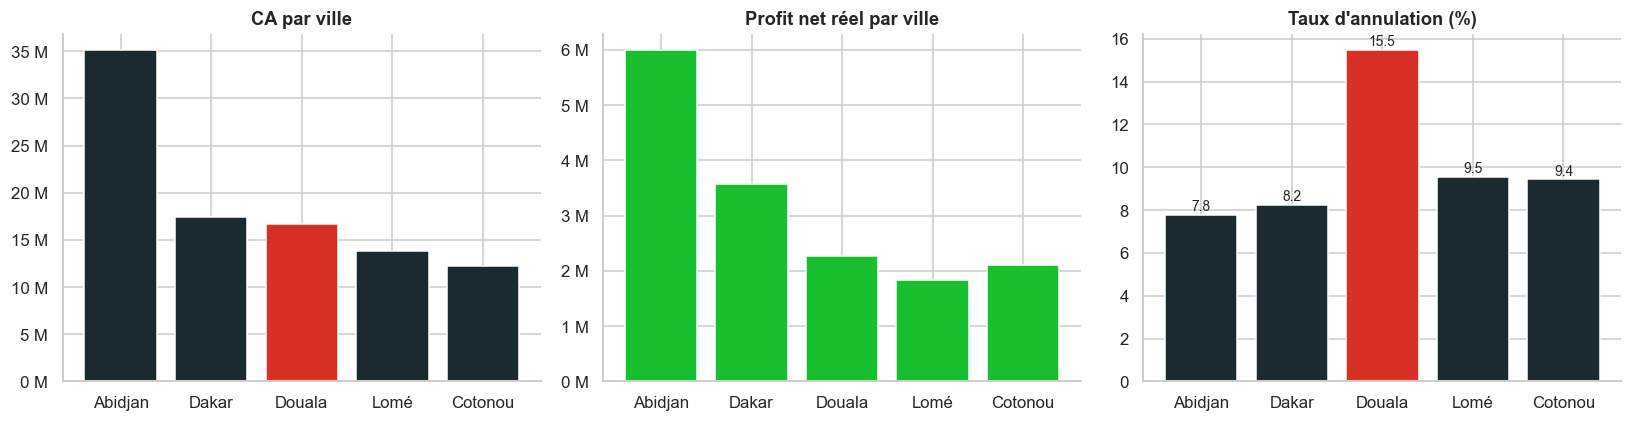

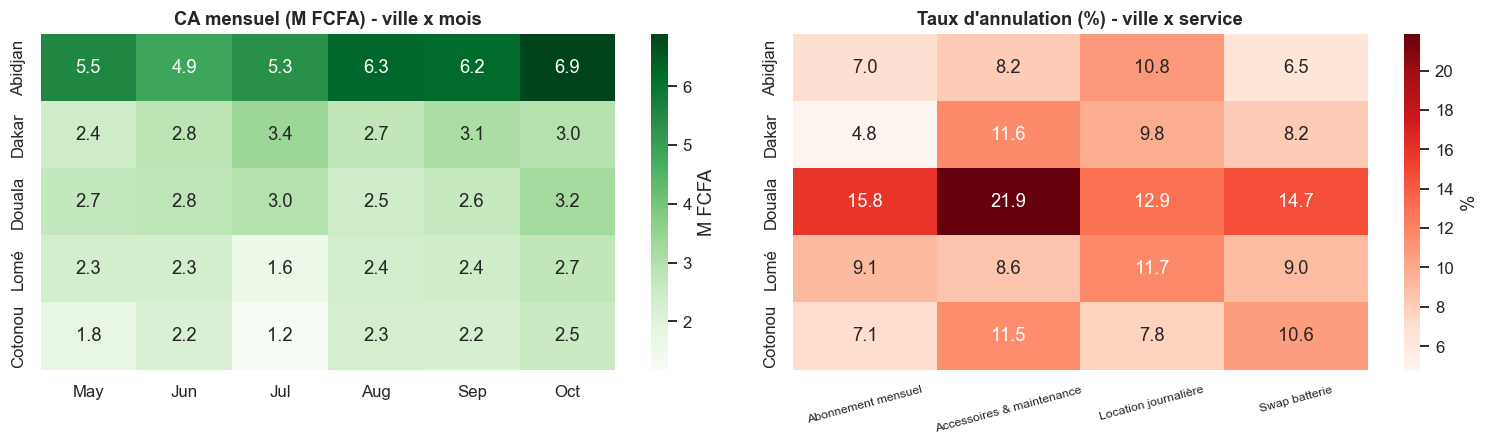

Productivité moyenne d'une station existante (par mois) :


,stations,transactions_mois,ca_mois,contribution_mois
ville,,,,
Abidjan,8,44.71,"724,793.07","181,575.93"
Dakar,8,23.00,"357,912.97","94,377.34"
Douala,8,23.67,"346,177.92","87,287.92"
Lomé,8,19.23,"286,284.06","69,216.20"
Cotonou,8,15.23,"250,769.95","66,197.47"


In [15]:
vl = group_table(df, "ville").sort_values("ca", ascending=False)
mv = monthly(df, "ville").pivot(index="mois", columns="ville", values="ca")
vl["croissance_T2_vs_T1"] = (mv.iloc[3:].sum() / mv.iloc[:3].sum() - 1)   # 3 derniers mois vs 3 premiers
vl["profit_reel_pct_ca"] = vl.profit_net_reel / vl.ca
display(vl[["transactions", "ca", "profit_net", "profit_net_reel", "profit_reel_pct_ca", "taux_annulation", "taux_remboursement",
            "croissance_T2_vs_T1", "panier_moyen"]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = [ROUGE if v == "Douala" else ANTHRACITE for v in vl.index]
axes[0].bar(vl.index, vl.ca, color=colors); axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(millions)); axes[0].set_title("CA par ville")
axes[1].bar(vl.index, vl.profit_net_reel, color=VERT); axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(millions)); axes[1].set_title("Profit net réel par ville")
axes[2].bar(vl.index, vl.taux_annulation * 100, color=colors); axes[2].set_title("Taux d'annulation (%)")
for i, v in enumerate(vl.taux_annulation * 100): axes[2].text(i, v + 0.2, f"{v:.1f}", ha="center", fontsize=9)
plt.tight_layout(); save(fig, "05_villes.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
hm = mv.copy(); hm.index = hm.index.strftime("%b"); hm = hm.T.loc[vl.index]
sns.heatmap(hm / 1e6, annot=True, fmt=".1f", cmap="Greens", ax=axes[0], cbar_kws={"label": "M FCFA"}); axes[0].set_title("CA mensuel (M FCFA) - ville x mois"); axes[0].set_xlabel(""); axes[0].set_ylabel("")
an = df.pivot_table(index="ville", columns="type_service", values="indicateur_annulation", aggfunc="mean").loc[vl.index] * 100
sns.heatmap(an, annot=True, fmt=".1f", cmap="Reds", ax=axes[1], cbar_kws={"label": "%"}); axes[1].set_title("Taux d'annulation (%) - ville x service"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
axes[1].tick_params(axis="x", labelrotation=15, labelsize=8)
plt.tight_layout(); save(fig, "06_heatmaps_villes.png"); plt.show()

an_m = df.pivot_table(index="mois", columns="ville", values="indicateur_annulation", aggfunc="mean") * 100
fig = px.line(an_m.reset_index().melt("mois", value_name="annulation", var_name="ville"), x="mois", y="annulation", color="ville",
              markers=True, title="Interactif - Taux d'annulation mensuel par ville (%)", color_discrete_sequence=PALETTE_CAT)
fig.update_layout(height=360, legend=dict(orientation="h", y=-0.2)); fig.show()

st = station_table(df)
stv = st.groupby("ville").agg(stations=("station", "size"), transactions_mois=("transactions_mensuelles", "mean"),
                              ca_mois=("ca_mensuel", "mean"), contribution_mois=("contribution_mensuelle", "mean")).loc[vl.index]
print("Productivité moyenne d'une station existante (par mois) :")
display(stv)

**Lecture business.**
* **Abidjan** pèse 37 % du CA et **ses stations sont 2 fois plus productives** que les autres (181 k FCFA de contribution mensuelle par station contre 66-94 k ailleurs ; 45 transactions/mois contre 15-24) : la demande y dépasse l'offre de stations. Croissance : +23 %.
* **Cotonou** est la petite ville qui **accélère le plus (+38 %)**, mais par station elle reste la moins productive (15 transactions/mois) : le potentiel est là, la maturité non.
* **Lomé** progresse (+19 %), avec un taux de remboursement élevé (8,4 %).
* **Dakar** est stable (+2 %) mais **la plus saine** : annulation 8,2 %, remboursement le plus bas (6,2 %), le meilleur profit réel rapporté au CA.
* **Douala est le problème d'exécution** : **15,5 % d'annulation** (le double des autres), **à tous les mois** (12-17 %), **dans la quasi-totalité des stations** (jusqu'à 19 %) et surtout sur les services à engagement (abonnement 15,8 %, accessoires 21,9 %). CA stable (−1 %). Un défaut persistant et généralisé est **structurel** (disponibilité des batteries, logistique, process), pas un accident local.

In [16]:
# Score d'attractivité pour répartir les 20 stations (pondérations explicites, modifiables)
poids = {"contribution": 0.35, "croissance": 0.30, "execution": 0.20, "qualite": 0.15}
sc = pd.DataFrame({"contribution": stv.contribution_mois, "croissance": vl.croissance_T2_vs_T1,
                   "execution": 1 - vl.taux_annulation, "qualite": vl.profit_reel_pct_ca})
norm = (sc - sc.min()) / (sc.max() - sc.min())
sc["score"] = sum(norm[c] * w for c, w in poids.items())
sc = sc.sort_values("score", ascending=False)
display(sc.round(3))

# Répartition proposée des 20 stations
repartition = pd.DataFrame({"stations": {"Abidjan": 8, "Dakar": 4, "Cotonou": 3, "Lomé": 3, "Douala": 2}})
repartition["vague"] = ["Vague 1 (T1 2027)", "Vague 1 (T1 2027)", "Vague 1 (T1 2027)", "Vague 1 (T1 2027)", "Vague 2 - conditionnelle (taux d'annulation < 10 %)"]
repartition["stations_existantes"] = stv.stations
repartition["score"] = sc.score
display(repartition.sort_values("score", ascending=False))
assert repartition.stations.sum() == 20

,contribution,croissance,execution,qualite,score
ville,,,,,
Abidjan,"181,575.93",0.23,0.92,0.17,0.81
Cotonou,"66,197.47",0.38,0.91,0.17,0.54
Dakar,"94,377.34",0.02,0.92,0.20,0.44
Lomé,"69,216.20",0.20,0.91,0.13,0.32
Douala,"87,287.92",-0.01,0.84,0.14,0.07


,stations,vague,stations_existantes,score
Abidjan,8,Vague 1 (T1 2027),8,0.81
Cotonou,3,Vague 1 (T1 2027),8,0.54
Dakar,4,Vague 1 (T1 2027),8,0.44
Lomé,3,Vague 1 (T1 2027),8,0.32
Douala,2,Vague 2 - conditionnelle (taux d'annulation < ...,8,0.07


**Réponse à la question stratégique — où ouvrir les 20 stations ? où corriger d'abord ?**

| Ville | Stations | Raison |
|---|---|---|
| **Abidjan** | **8** | Stations 2x plus productives, demande saturée, +23 % de croissance ; c'est là qu'une station neuve se rentabilise le plus vite (§5.3) |
| **Dakar** | **4** | Ville la plus saine (annulation et remboursement bas) ; croissance faible → ouvrir en renforcement, pas en pari |
| **Cotonou** | **3** | Plus forte croissance (+38 %) mais productivité encore faible → ouvrir par paliers |
| **Lomé** | **3** | +19 % de croissance ; surveiller les remboursements |
| **Douala** | **2, conditionnelles** | **Corriger l'exécution d'abord** : ouvrir seulement si l'annulation passe sous 10 % |

Le score classe Abidjan très nettement en tête et Douala en dernier. **Cotonou passe devant Dakar au score uniquement grâce à sa croissance (+38 %)**, mais c'est la ville où une station neuve se rentabilise le moins (§5.3) : on l'ouvre donc **par paliers (3)**, et on renforce **Dakar (4)**, plus productive et plus saine. La répartition finale combine ainsi le score, le point mort et le **risque d'exécution** (on ne finance pas une ouverture là où 1 commande sur 6 est annulée). Ordre des priorités : **Abidjan > Dakar > Cotonou ≈ Lomé > Douala (après correction)**.

## 4.4 Analyse marketing (acquisition)

,ca,marketing,part_marketing,part_ca,roi_marketing,roi_marge,cout_par_transaction,profit_net_reel,taux_annulation,taux_remboursement,retention
canal_acquisition,,,,,,,,,,,
Parrainage,"16,913,020.00","458,453.00",0.07,0.18,35.89,11.13,441.24,"3,857,427.00",0.09,0.06,0.73
WhatsApp Business,"14,034,940.00","566,417.00",0.09,0.15,23.78,7.01,624.50,"2,559,415.50",0.09,0.08,0.68
Partenariat chauffeurs VTC,"18,041,007.50","874,740.00",0.13,0.19,19.62,5.79,793.06,"3,801,897.50",0.10,0.07,0.66
Affichage & stations,"9,972,202.50","927,458.50",0.14,0.11,9.75,2.43,"1,286.35","1,441,921.50",0.09,0.06,0.63
Meta Ads,"17,412,107.50","1,750,607.00",0.26,0.19,8.95,2.23,"1,574.29","2,592,895.50",0.08,0.07,0.66
TikTok Ads,"17,046,730.00","2,033,380.00",0.31,0.18,7.38,1.67,"1,820.39","1,201,812.50",0.13,0.11,0.61


(Non renseigné exclu : 111 transactions, 1,98 % du CA)


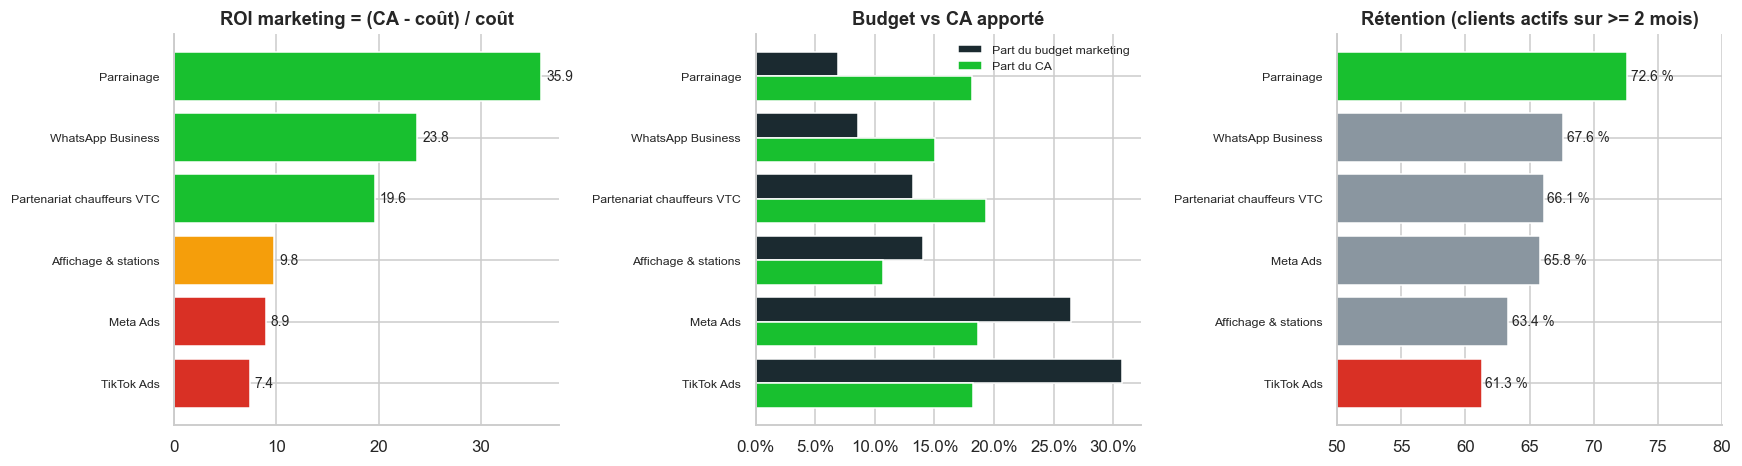

Swap uniquement : profit net par canal d'acquisition


,transactions,profit_net,cout_mkt_moyen,marge_moy
canal_acquisition,,,,
TikTok Ads,515,"-340,074.00","1,831.70","1,171.36"
Meta Ads,549,"-176,530.50","1,568.40","1,246.85"
Affichage & stations,392,"-44,084.00","1,294.83","1,182.37"
Non renseigné,58,"16,612.00",946.86,"1,233.28"
Partenariat chauffeurs VTC,514,"244,335.00",794.82,"1,270.18"
WhatsApp Business,444,"284,018.50",613.89,"1,253.58"
Parrainage,512,"391,008.00",434.84,"1,198.53"


In [17]:
cn = group_table(df[df.canal_acquisition != NON_RENSEIGNE], "canal_acquisition").sort_values("roi_marketing", ascending=False)
cn["cout_par_transaction"] = cn.marketing / cn.transactions
cc = client_table(df)
cn["retention"] = cc.groupby("canal").retenu.mean()
cn["clients"] = cc.groupby("canal").size()
cn["part_marketing"] = cn.marketing / cn.marketing.sum()
display(cn[["ca", "marketing", "part_marketing", "part_ca", "roi_marketing", "roi_marge", "cout_par_transaction", "profit_net_reel",
            "taux_annulation", "taux_remboursement", "retention"]])
print(f"({NON_RENSEIGNE} exclu : 111 transactions, 1,98 % du CA)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
roi = cn.roi_marketing.sort_values()
axes[0].barh(roi.index, roi, color=[VERT if v >= 15 else (ORANGE if v >= 9 else ROUGE) for v in roi])
for i, v in enumerate(roi): axes[0].text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=9)
axes[0].set_title("ROI marketing = (CA - coût) / coût"); axes[0].tick_params(axis="y", labelsize=8)
axes[1].barh(np.arange(len(cn)) - 0.2, cn.part_marketing, 0.4, color=ANTHRACITE, label="Part du budget marketing")
axes[1].barh(np.arange(len(cn)) + 0.2, cn.part_ca, 0.4, color=VERT, label="Part du CA")
axes[1].set_yticks(np.arange(len(cn))); axes[1].set_yticklabels(cn.index, fontsize=8); axes[1].invert_yaxis()
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].legend(frameon=False, fontsize=8); axes[1].set_title("Budget vs CA apporté")
rt = cn.retention.sort_values()
axes[2].barh(rt.index, rt * 100, color=[VERT if v >= .7 else (ROUGE if v < .63 else GRIS) for v in rt]); axes[2].set_xlim(50, 80)
for i, v in enumerate(rt * 100): axes[2].text(v + 0.3, i, f"{v:.1f} %", va="center", fontsize=9)
axes[2].set_title("Rétention (clients actifs sur >= 2 mois)"); axes[2].tick_params(axis="y", labelsize=8)
plt.tight_layout(); save(fig, "07_canaux.png"); plt.show()

fig = px.scatter(cn.reset_index(), x="marketing", y="roi_marketing", size="ca", color="taux_remboursement", text="canal_acquisition",
                 color_continuous_scale="RdYlGn_r", title="Interactif - Budget (x) vs ROI (y) ; taille = CA, couleur = taux de remboursement",
                 labels={"marketing": "Coût marketing (FCFA)", "roi_marketing": "ROI", "taux_remboursement": "Remb."})
fig.update_traces(textposition="top center"); fig.update_layout(height=430); fig.show()

swc = df[df.type_service == "Swap batterie"].groupby("canal_acquisition").agg(transactions=("profit_net", "size"), profit_net=("profit_net", "sum"),
                                                                           cout_mkt_moyen=("cout_marketing_fcfa", "mean"), marge_moy=("marge_brute", "mean")).sort_values("profit_net")
print("Swap uniquement : profit net par canal d'acquisition")
display(swc)

**Lecture business.**
* **Parrainage = le meilleur canal sur tous les critères** : ROI de **35,9**, coût de seulement **441 FCFA/transaction** (contre 1 820 pour TikTok), **72,6 % de rétention** (le meilleur), 6 % de remboursement. Il apporte 17,7 % du CA pour **6,8 % du budget**.
* **WhatsApp Business (ROI 23,8)** et **Partenariat chauffeurs VTC (ROI 19,6)** sont également rentables et fidélisants.
* **TikTok Ads est le canal à corriger** : **30 % du budget marketing** (2,03 M FCFA) pour 17,9 % du CA, **ROI le plus bas (7,4)**, **taux d'annulation 13,1 %**, **remboursement 11 %**, **rétention la plus faible (61,3 %)**. Son profit réel (1,2 M) est 3x inférieur à celui du parrainage (3,86 M) alors que le CA est équivalent.
* **Meta Ads** et **Affichage** ont un ROI moyen (9-10) mais un coût par transaction élevé (1 570 et 1 290 FCFA).
* **Effet sur le swap** : avec un panier de 3 500 FCFA, acquérir un client swap via TikTok (1 832 FCFA) ou Meta (1 568 FCFA) **fait perdre de l'argent** (profit swap : −340 k et −177 k FCFA), alors que Parrainage, WhatsApp et VTC dégagent un profit positif.

**Réponse à la question stratégique.**
* **Plus de budget :** Parrainage (programme à renforcer : bonus pour parrain et filleul), WhatsApp Business, Partenariat VTC.
* **À optimiser :** TikTok (cibler les abonnements et les PME plutôt que le swap, ou plafonner le coût d'acquisition), Meta Ads (même logique).
* **À réduire en premier :** la part de TikTok/Meta dédiée à l'acquisition de clients swap.

## 4.5 Analyse clients

Clients (toutes transactions)             : 1 098
Clients avec >= 1 transaction non annulée : 1 072
% de clients récurrents (>= 2 transactions): 70,0 %
% de clients retenus (actifs sur >= 2 mois) : 66,0 %

Pareto : 318 clients (29.7%) génèrent 80 % du CA ; les 20 % meilleurs en génèrent 69.9%


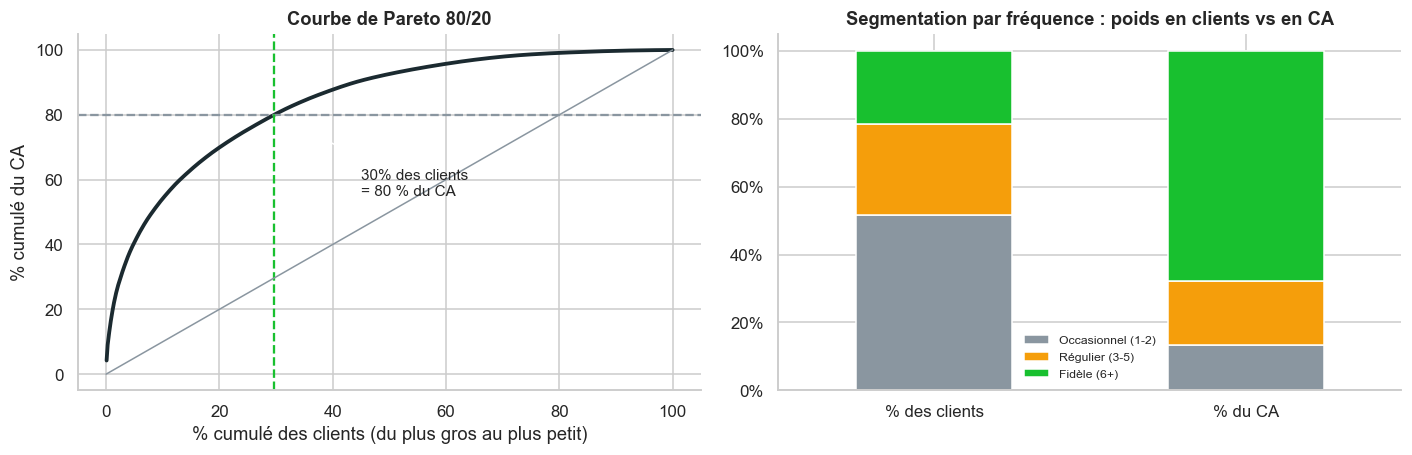

,clients,ca,profit,part_clients,part_ca
frequence,,,,,
Occasionnel (1-2),553,"12,813,050.00","3,288,995.00",0.52,0.13
Régulier (3-5),289,"17,799,920.00","4,556,165.00",0.27,0.19
Fidèle (6+),230,"64,690,852.50","17,036,937.50",0.21,0.68


Top 10 clients :


,type_client,canal,transactions,ca,profit_net,mois_actifs
client,,,,,,
CLI01077,Particulier,TikTok Ads,208,"4,018,315.00","827,822.00",6
CLI00113,PME / flotte,Partenariat chauffeurs VTC,96,"2,454,505.00","771,070.00",6
CLI00929,PME / flotte,Parrainage,82,"2,154,342.50","677,036.50",6
CLI00978,Chauffeur moto-taxi,TikTok Ads,65,"1,295,695.00","295,931.00",6
CLI00264,Particulier,WhatsApp Business,73,"1,295,005.00","339,577.00",6
CLI01055,Chauffeur moto-taxi,TikTok Ads,58,"1,170,867.50","277,364.50",6
CLI00846,Chauffeur moto-taxi,Affichage & stations,75,"1,135,540.00","264,908.00",6
CLI00749,PME / flotte,Parrainage,35,"1,126,070.00","375,366.00",6
CLI01279,Chauffeur moto-taxi,Meta Ads,67,"1,035,162.50","239,556.50",6


Les 10 premiers clients = 17.5% du CA ; type : {'PME / flotte': 4, 'Chauffeur moto-taxi': 4, 'Particulier': 2}


In [18]:
cl = client_table(df)
print(f"Clients (toutes transactions)             : {df.id_client.nunique():,}".replace(",", " "))
print(f"Clients avec >= 1 transaction non annulée : {len(cl):,}".replace(",", " "))
print(f"% de clients récurrents (>= 2 transactions): {pct(cl.recurrent.mean())}")
print(f"% de clients retenus (actifs sur >= 2 mois) : {pct(cl.retenu.mean())}")

p = pareto(cl, "ca")
n80 = int((p.part_cum <= 0.8).sum() + 1)
print(f"\nPareto : {n80} clients ({n80/len(p):.1%}) génèrent 80 % du CA ; les 20 % meilleurs en génèrent {p.part_cum.iloc[int(len(p)*.2)-1]:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(p.pct_clients * 100, p.part_cum * 100, color=ANTHRACITE, lw=2.5)
axes[0].axhline(80, color=GRIS, ls="--"); axes[0].axvline(n80 / len(p) * 100, color=VERT, ls="--")
axes[0].plot([0, 100], [0, 100], color=GRIS, lw=1)
axes[0].annotate(f"{n80/len(p):.0%} des clients\n= 80 % du CA", (n80 / len(p) * 100, 80), (45, 55), arrowprops=dict(arrowstyle="->"), fontsize=10)
axes[0].set_xlabel("% cumulé des clients (du plus gros au plus petit)"); axes[0].set_ylabel("% cumulé du CA"); axes[0].set_title("Courbe de Pareto 80/20")
seg = cl.groupby("frequence", observed=True).agg(clients=("ca", "size"), ca=("ca", "sum"), profit=("profit_net", "sum"))
seg["part_clients"] = seg.clients / seg.clients.sum(); seg["part_ca"] = seg.ca / seg.ca.sum()
seg[["part_clients", "part_ca"]].T.plot(kind="bar", stacked=True, ax=axes[1], color=[GRIS, ORANGE, VERT], width=0.5)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].set_title("Segmentation par fréquence : poids en clients vs en CA")
axes[1].set_xticklabels(["% des clients", "% du CA"], rotation=0); axes[1].legend(fontsize=8, frameon=False)
plt.tight_layout(); save(fig, "08_pareto_segments.png"); plt.show()
display(seg)

top10 = cl.sort_values("ca", ascending=False).head(10)[["type_client", "canal", "transactions", "ca", "profit_net", "mois_actifs"]]
top10.index.name = "client"
print("Top 10 clients :"); display(top10)
print(f"Les 10 premiers clients = {top10.ca.sum()/cl.ca.sum():.1%} du CA ; type : {top10.type_client.value_counts().to_dict()}")

**Lecture business.**
* **Portefeuille concentré :** **30 % des clients (318) font 80 % du CA** ; les **230 clients « fidèles »** (6+ transactions, 21 % des clients) génèrent **68 % du CA**. À l'inverse, 52 % des clients sont occasionnels (1-2 transactions) et ne pèsent que 13 % du CA.
* **70 % de clients récurrents**, **66 % actifs sur au moins 2 mois** : la base est fidèle, mais **le nombre de clients actifs décroît avec l'ancienneté** (365 clients actifs 1 seul mois, 82 sur les 6 mois) — l'enjeu est la **rétention des occasionnels**, pas l'acquisition à tout prix.
* Le **top 10 pèse 17,5 % du CA** (le n° 1 à lui seul : 4,0 M FCFA, 208 transactions) : un risque de dépendance à surveiller (4 PME/flottes, 4 chauffeurs, 2 particuliers).

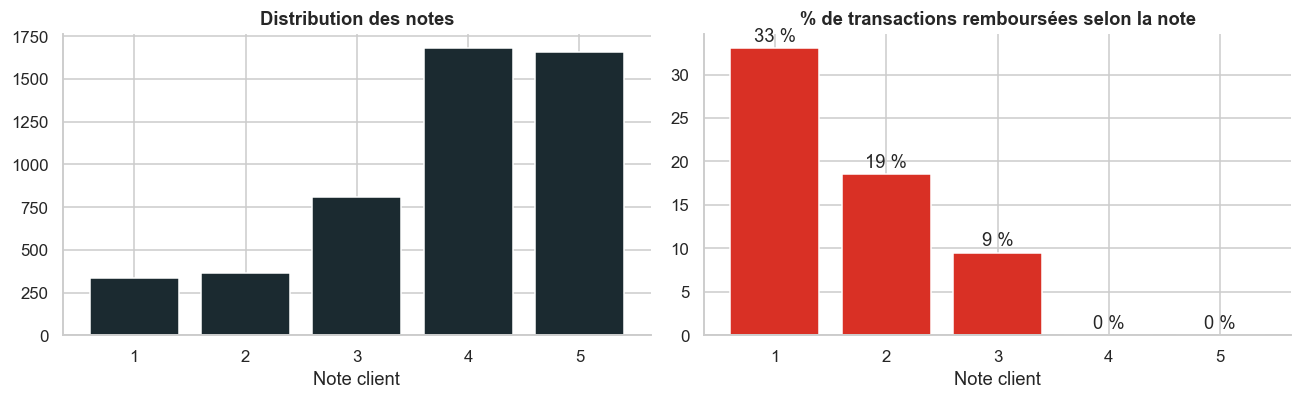

Note moyenne : 3.82/5  |  terminées : 3.93  |  remboursées : 1.87
Part de notes <= 2 : 14.4% ; parmi elles, 25% sont remboursées ; aucune note >= 4 n'est remboursée.
Notes manquantes : 10 % des terminées, 38 % des remboursées -> les clients mécontents répondent moins.


In [19]:
# --- Satisfaction et remboursement
nt = df.dropna(subset=["note_client"]).copy()
nt["note"] = nt.note_client.astype(int)
by_note = nt.groupby("note").agg(transactions=("note", "size"), taux_remb=("indicateur_remboursement", "mean"))
mean_notes = df.groupby("statut").note_client.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(by_note.index, by_note.transactions, color=ANTHRACITE); axes[0].set_title("Distribution des notes"); axes[0].set_xlabel("Note client")
axes[1].bar(by_note.index, by_note.taux_remb * 100, color=ROUGE); axes[1].set_title("% de transactions remboursées selon la note"); axes[1].set_xlabel("Note client")
for i, v in zip(by_note.index, by_note.taux_remb * 100): axes[1].text(i, v + 0.8, f"{v:.0f} %", ha="center")
plt.tight_layout(); save(fig, "09_satisfaction.png"); plt.show()
print(f"Note moyenne : {df.note_client.mean():.2f}/5  |  terminées : {mean_notes['Terminée']:.2f}  |  remboursées : {mean_notes['Remboursée']:.2f}")
print(f"Part de notes <= 2 : {(df.note_client <= 2).sum()/df.note_client.notna().sum():.1%} ; parmi elles, {df[df.note_client <= 2].indicateur_remboursement.mean():.0%} sont remboursées ; "
      f"aucune note >= 4 n'est remboursée.")
print("Notes manquantes : 10 % des terminées, 38 % des remboursées -> les clients mécontents répondent moins.")

**Lecture business.**
* Note moyenne **3,82/5**. Les transactions remboursées sont notées **1,87** contre **3,93** pour les terminées. **Aucune note ≥ 4 n'est remboursée ; 1 note ≤ 2 sur 4 l'est.**
* **La note est donc un signal d'alerte précoce** : une note ≤ 2 prédit un remboursement. Agir **avant** le remboursement (rappel du client, geste commercial, échange de batterie) coûte moins cher que rembourser (8,4 M FCFA remboursés sur la période).
* 38 % des transactions remboursées n'ont pas de note : le sondage doit être **systématique et immédiat** (SMS/WhatsApp post-service).

In [20]:
# --- Conversion swap -> abonnement mensuel
e = df[df.statut != "Annulée"]
mix = e.pivot_table(index="id_client", columns="type_service", values="quantite", aggfunc="sum", fill_value=0)
swap_cl = mix[mix["Swap batterie"] > 0]
a_abo = swap_cl["Abonnement mensuel"] > 0
swap_only = swap_cl[~a_abo].index
print(f"Clients ayant utilisé le swap : {len(swap_cl)} | dont déjà abonnés : {a_abo.sum()} ({a_abo.mean():.0%}) | swap uniquement : {len(swap_only)}")

abo = e[e.type_service == "Abonnement mensuel"]
abo_marge_mois = abo.marge_brute.sum() / abo.quantite.sum()
sw_only = e[(e.type_service == "Swap batterie") & e.id_client.isin(swap_only)]
sw_marge_mois = sw_only.groupby("id_client").marge_brute.sum().mean() / 6
gain_net_mois = abo_marge_mois - sw_marge_mois
print(f"Marge brute mensuelle d'un abonné = {abo_marge_mois:,.0f} FCFA ; marge swap mensuelle d'un client 'swap uniquement' = {sw_marge_mois:,.0f} FCFA".replace(",", " "))

H = {"mois_abonnement_moyen": 3}
scen = pd.DataFrame({"taux de conversion": [0.05, 0.10, 0.15, 0.20]})
scen["clients convertis"] = (len(swap_only) * scen["taux de conversion"]).round().astype(int)
scen["gain de marge (M FCFA / 6 mois)"] = scen["clients convertis"] * gain_net_mois * H["mois_abonnement_moyen"] / 1e6
scen["en % du profit net actuel"] = scen["gain de marge (M FCFA / 6 mois)"] * 1e6 / df.profit_net.sum()
display(scen)
print("Hypothèse : chaque client converti garde l'abonnement 3 mois en moyenne et abandonne ses swaps ; le gain = marge abonnement - marge swap perdue.")

Clients ayant utilisé le swap : 833 | dont déjà abonnés : 364 (44%) | swap uniquement : 469
Marge brute mensuelle d'un abonné = 9 584 FCFA ; marge swap mensuelle d'un client 'swap uniquement' = 400 FCFA


,taux de conversion,clients convertis,gain de marge (M FCFA / 6 mois),en % du profit net actuel
0,0.05,23,0.63,0.03
1,0.10,47,1.29,0.05
2,0.15,70,1.93,0.08
3,0.20,94,2.59,0.11


Hypothèse : chaque client converti garde l'abonnement 3 mois en moyenne et abandonne ses swaps ; le gain = marge abonnement - marge swap perdue.


**Lecture business — comment convertir le swap en abonnement ?**
* **44 % des clients swap** ont déjà un abonnement : la bascule se produit naturellement pour une partie d'entre eux. Il reste **469 clients « swap uniquement »** à convertir.
* Un abonné rapporte ≈ **9 600 FCFA de marge par mois** contre ≈ **400 FCFA** pour un client « swap uniquement » : **une conversion rapporte ~9 000 FCFA de marge supplémentaire par mois**. Attention : ces clients dépensent aujourd'hui peu en swap (≈ 2 700 FCFA/mois de CA) alors que l'abonnement coûte 28 000 FCFA : un taux de conversion réaliste se situe plutôt à **5-10 %** et la cible prioritaire doit être celle des gros utilisateurs.
* **5 à 10 % de conversion** (23 à 47 clients) apporterait **0,6 à 1,3 M FCFA de marge sur 6 mois** (3 à 5 % du profit net), sans coût d'acquisition puisque ces clients sont déjà acquis.

**Actions proposées :** (1) proposer l'abonnement **dès le 5ᵉ swap** (« vous avez payé X FCFA ce mois, l'abonnement vous coûterait Y ») ; (2) abonnement **d'essai** ou 1er mois à tarif réduit **plafonné** (et non des remises générales, §5.2) ; (3) cibler d'abord les **59 clients « swap uniquement » ayant fait au moins 8 swaps**, les plus proches de l'équivalent d'un abonnement ; (4) objectif de **rétention** : relancer tout client occasionnel ayant un 2ᵉ mois sans transaction.

# 5. Bonus senior

## 5.1 Quel segment client est le plus rentable ?

,transactions,ca,part_ca,panier_moyen,marge_pct,taux_annulation,taux_remboursement,roi_marketing,profit_par_transaction,profit_reel_par_transaction,profit_net_reel
type_client,,,,,,,,,,,
PME / flotte,889,"19,359,907.50",0.21,"23,638.47",0.34,0.08,0.06,22.09,"6,356.58","5,063.63","4,501,569.50"
Chauffeur moto-taxi,2570,"37,862,300.00",0.40,"16,208.18",0.33,0.09,0.06,12.16,"3,799.09","2,761.58","7,097,256.00"
Livreur,1160,"14,615,632.50",0.15,"14,107.75",0.32,0.11,0.06,10.68,"3,003.71","1,678.24","1,946,760.00"
Particulier,1437,"22,521,500.00",0.24,"17,691.67",0.30,0.11,0.12,12.27,"3,502.65","1,440.94","2,070,633.50"


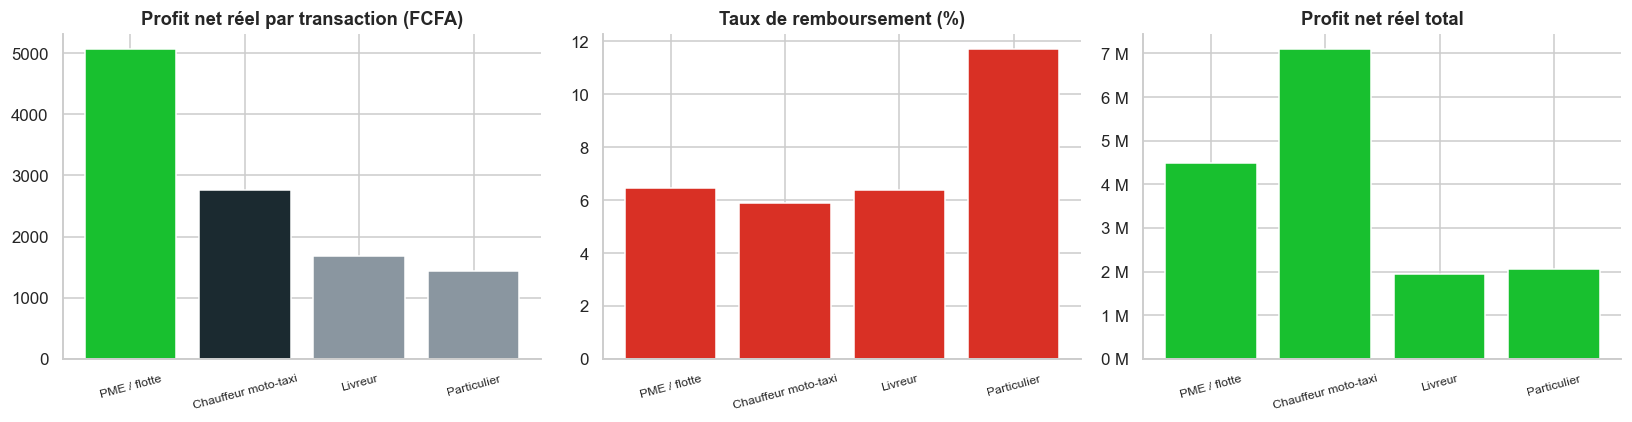

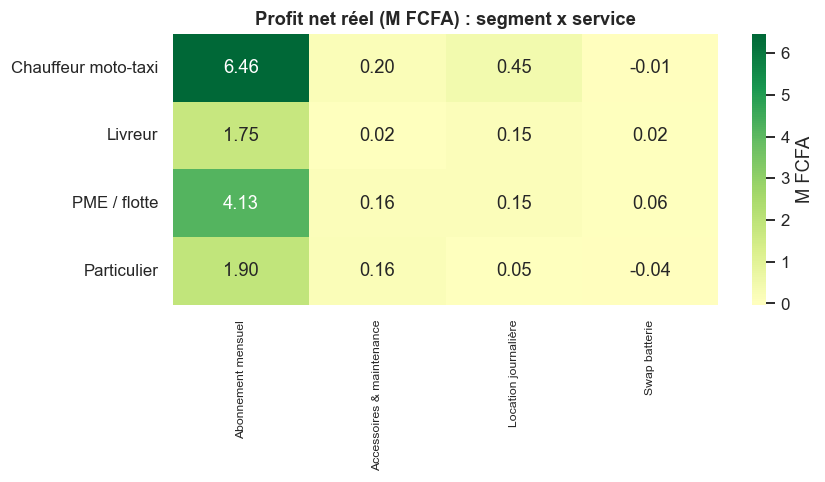

In [21]:
sg = group_table(df[df.type_client != NON_RENSEIGNE], "type_client")
sg["profit_reel_par_transaction"] = sg.profit_net_reel / sg.transactions
sg["profit_par_transaction"] = sg.profit_net / sg.transactions
sg = sg.sort_values("profit_reel_par_transaction", ascending=False)
display(sg[["transactions", "ca", "part_ca", "panier_moyen", "marge_pct", "taux_annulation", "taux_remboursement", "roi_marketing",
            "profit_par_transaction", "profit_reel_par_transaction", "profit_net_reel"]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(sg.index, sg.profit_reel_par_transaction, color=[VERT, ANTHRACITE, GRIS, GRIS]); axes[0].set_title("Profit net réel par transaction (FCFA)")
axes[1].bar(sg.index, sg.taux_remboursement * 100, color=ROUGE); axes[1].set_title("Taux de remboursement (%)")
axes[2].bar(sg.index, sg.profit_net_reel, color=VERT); axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(millions)); axes[2].set_title("Profit net réel total")
for a in axes: a.tick_params(axis="x", labelrotation=15, labelsize=8)
plt.tight_layout(); save(fig, "10_segments_clients.png"); plt.show()

pv = df[df.type_client != NON_RENSEIGNE].pivot_table(index="type_client", columns="type_service", values="profit_net_reel", aggfunc="sum") / 1e6
plt.figure(figsize=(8, 3.2)); sns.heatmap(pv, annot=True, fmt=".2f", cmap="RdYlGn", center=0, cbar_kws={"label": "M FCFA"})
plt.title("Profit net réel (M FCFA) : segment x service"); plt.xlabel(""); plt.ylabel(""); plt.xticks(fontsize=8); plt.show()

**Lecture business.**
* **PME / flotte = segment le plus rentable par transaction** : panier le plus haut (23 600 FCFA), meilleure marge (33,5 %), annulation la plus basse (7,9 %), ROI marketing 22 et **5 064 FCFA de profit réel par transaction** (le double des chauffeurs : 2 762).
* **Chauffeurs moto-taxi = le volume** (40 % du CA, 7,1 M de profit réel), rentables essentiellement grâce à l'**abonnement** (6,5 M).
* **Particuliers = le segment le moins rentable** : **11,7 % de remboursement**, marge de 29,9 %, et un profit réel par transaction de 1 441 FCFA ; le **swap des particuliers perd de l'argent** (−40 k FCFA). Ils achètent surtout de la location et des accessoires, les services les plus remboursés.
* **Livreurs** : correct mais le plus exposé aux annulations (10,7 %) ; potentiel via l'abonnement.

**Recommandation segmentée :** développer la **prospection PME/flottes** (contrats flotte, facturation mensuelle), sécuriser les moto-taxis par l'abonnement, et **traiter la qualité de service avant d'acquérir de nouveaux particuliers**.

## 5.2 Les promotions détruisent-elles de la valeur ?

,transactions,quantite_moy,panier_moy,marge_par_trans,taux_remb,profit_reel,marge_pct,taux_annulation
remise_tranche,,,,,,,,
0 %,3671,2.42,"18,103.80","6,305.20",0.07,"13,675,751.50",0.35,0.10
5 %,647,2.39,"15,624.05","4,846.46",0.08,"1,414,321.50",0.31,0.10
10 %,646,2.46,"16,431.13","4,511.08",0.08,"1,270,142.00",0.27,0.09
15 %,365,2.37,"15,255.40","3,473.35",0.07,"274,450.00",0.23,0.11
20 %,184,2.48,"13,876.52","2,421.09",0.12,"-142,365.00",0.17,0.11


33.5% des transactions sont remisées ; CA sacrifié = 3.33 M FCFA = 3.5% du CA = 10.8% de la marge brute.


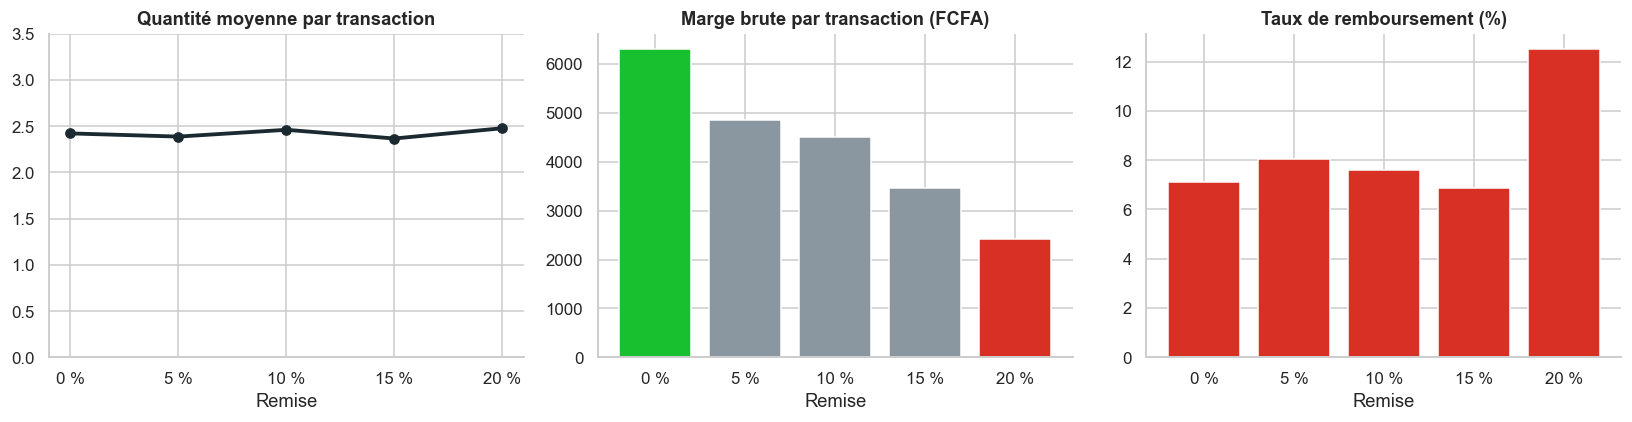

In [22]:
e = df[df.statut != "Annulée"]
rm = e.groupby("remise_tranche", observed=True).agg(transactions=("quantite", "size"), quantite_moy=("quantite", "mean"),
                                                   panier_moy=("chiffre_affaires", "mean"), marge_par_trans=("marge_brute", "mean"),
                                                   taux_remb=("indicateur_remboursement", "mean"), profit_reel=("profit_net_reel", "sum"))
rm["marge_pct"] = e.groupby("remise_tranche", observed=True).marge_brute.sum() / e.groupby("remise_tranche", observed=True).chiffre_affaires.sum()
ann = df.groupby("remise_tranche", observed=True).indicateur_annulation.mean()
rm["taux_annulation"] = ann
display(rm)
ca_sacrifie = (e.quantite * e.prix_unitaire_fcfa * e.remise_pct / 100).sum()
print(f"{(df.remise_pct > 0).mean():.1%} des transactions sont remisées ; CA sacrifié = {M(ca_sacrifie)} FCFA = {ca_sacrifie/df.chiffre_affaires.sum():.1%} du CA = {ca_sacrifie/df.marge_brute.sum():.1%} de la marge brute.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(rm.index.astype(str), rm.quantite_moy, "o-", color=ANTHRACITE, lw=2.5); axes[0].set_ylim(0, 3.5)
axes[0].set_title("Quantité moyenne par transaction"); axes[0].set_xlabel("Remise");
axes[1].bar(rm.index.astype(str), rm.marge_par_trans, color=[VERT, GRIS, GRIS, GRIS, ROUGE]); axes[1].set_title("Marge brute par transaction (FCFA)"); axes[1].set_xlabel("Remise")
axes[2].bar(rm.index.astype(str), rm.taux_remb * 100, color=ROUGE); axes[2].set_title("Taux de remboursement (%)"); axes[2].set_xlabel("Remise")
plt.tight_layout(); save(fig, "11_remises.png"); plt.show()

**Lecture business : OUI, les remises détruisent de la valeur.**
* **Aucun effet volume** : la quantité moyenne par transaction est **plate** (2,42 sans remise → 2,48 à 20 %) ; le taux d'annulation aussi. Les remises ne font pas acheter plus.
* **Effet marge sévère** : la marge par transaction passe de **6 305 FCFA (sans remise) à 2 421 FCFA (−62 %) à 20 %**.
* **À 20 % de remise, le remboursement bondit à 12,5 %** (contre 7 % sans remise) et le **profit réel devient négatif** (−142 k FCFA sur les transactions non annulées).
* **Coût total : 3,3 M FCFA de CA sacrifié**, soit 3,5 % du CA mais **10,8 % de la marge brute**. Un tiers des transactions (33,5 %) est remisé sans différence de comportement : les remises sont **accordées par habitude, pas par stratégie**.

**Recommandation :** supprimer les remises ≥ 15 % ; réserver 5-10 % à des objectifs précis (essai d'abonnement, contrat flotte, parrainage) avec suivi du ROI ; instaurer une validation au-delà de 10 %.

## 5.3 Point mort d'une nouvelle station

### Hypothèses (à valider avec la Finance)
Le dataset donne la **marge de contribution** d'une station (marge brute − marketing), mais pas ses charges fixes ni son investissement. Les hypothèses suivantes sont **cohérentes avec l'échelle d'activité observée** (CA moyen d'une station ≈ 400 k FCFA/mois) ; elles sont **volontairement modifiables** (cellule ci-dessous et dashboard Streamlit) :

| Hypothèse | Valeur | Justification |
|---|---|---|
| Investissement initial (capex) | **2,5 M FCFA** | Borne de charge/échange, enseigne, installation, stock initial de batteries |
| Charges fixes mensuelles | **45 k FCFA** | Loyer d'emplacement, agent à temps partiel, énergie fixe, connexion |
| Montée en charge | **3 mois à 50 %** de la contribution de croisière | Le temps de faire connaître la station |
| Contribution de croisière | **Moyenne observée des stations de la ville** | Mesurée sur 6 mois de données réelles |
| Horizon | 72 mois | |

**Point mort = mois où le cash cumulé (après capex) redevient positif.** Le *point mort mensuel* (équilibre d'exploitation) est le 1er mois où contribution ≥ charges fixes.

,contribution_mensuelle,transactions_mois_observees,contribution_par_transaction,transactions_pour_equilibre,mois_equilibre_mensuel,mois_point_mort_cash
ville,,,,,,
Abidjan,"181,575.93",44.71,"4,061.34",11.08,1,21.00
Dakar,"94,377.34",23.00,"4,103.36",10.97,1,54.00
Douala,"87,287.92",23.67,"3,688.22",12.20,4,63.00
Lomé,"69,216.20",19.23,"3,599.54",12.50,4,> 72
Cotonou,"66,197.47",15.23,"4,346.76",10.35,4,> 72


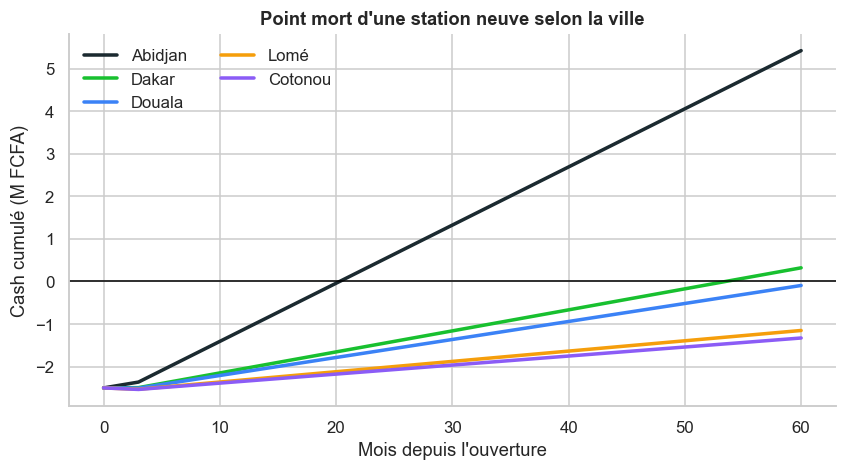

Sensibilité - mois de point mort cash d'une station 'moyenne' (contribution = 99 731 FCFA/mois) :


,charges fixes 30 k,charges fixes 45 k,charges fixes 60 k
contribution observée,38,49,67
+20 %,30,36,45
+40 %,25,29,35


In [23]:
HYP = dict(capex=2_500_000, charges_fixes=45_000, montee_en_charge=3, taux_initial=0.5)

rows = []
for ville, g in station_table(df).groupby("ville"):
    c = g.contribution_mensuelle.mean()
    be = breakeven(c, HYP["capex"], HYP["charges_fixes"], HYP["montee_en_charge"], HYP["taux_initial"])
    marge_trans = (g.marge.sum() - g.marketing.sum()) / g.transactions.sum()
    rows.append({"ville": ville, "contribution_mensuelle": c, "transactions_mois_observees": g.transactions_mensuelles.mean(),
                 "contribution_par_transaction": marge_trans,
                 "transactions_pour_equilibre": HYP["charges_fixes"] / marge_trans,
                 "mois_equilibre_mensuel": be["mois_equilibre_mensuel"], "mois_point_mort_cash": be["mois_retour"]})
pm = pd.DataFrame(rows).set_index("ville").sort_values("contribution_mensuelle", ascending=False)
display(pm.fillna("> 72"))

horizon = np.arange(0, 61)
fig, ax = plt.subplots(figsize=(9, 4.4))
for (ville, r), col in zip(pm.iterrows(), PALETTE_CAT):
    cum = [-HYP["capex"]]
    for m in range(1, 61):
        cum.append(cum[-1] + r.contribution_mensuelle * (HYP["taux_initial"] if m <= HYP["montee_en_charge"] else 1) - HYP["charges_fixes"])
    ax.plot(horizon, np.array(cum) / 1e6, label=ville, color=col, lw=2.3)
ax.axhline(0, color="black", lw=1); ax.set_xlabel("Mois depuis l'ouverture"); ax.set_ylabel("Cash cumulé (M FCFA)")
ax.set_title("Point mort d'une station neuve selon la ville"); ax.legend(frameon=False, ncol=2)
save(fig, "12_point_mort.png"); plt.show()

# Sensibilité : station "moyenne" (toutes villes) selon la contribution et les charges fixes
c_moy = station_table(df).contribution_mensuelle.mean()
sens = pd.DataFrame({f"charges fixes {int(f/1e3)} k": [breakeven(c_moy * (1 + u), HYP["capex"], f)["mois_retour"] or np.nan for u in [0, .2, .4]]
                     for f in [30_000, 45_000, 60_000]}, index=["contribution observée", "+20 %", "+40 %"])
print(f"Sensibilité - mois de point mort cash d'une station 'moyenne' (contribution = {c_moy:,.0f} FCFA/mois) :".replace(",", " "))
display(sens.fillna("> 72"))

**Lecture business.**
* **Abidjan : point mort cash en ~21 mois** — c'est la seule ville où l'investissement est repris en moins de 2 ans. Une station abidjanaise a besoin de ~11 transactions/mois pour couvrir ses charges fixes et en réalise 45.
* **Dakar (~54 mois) et Douala (~63 mois)** : l'activité couvre les charges fixes mais l'investissement est très long à récupérer. **Cotonou et Lomé** n'atteignent pas le point mort cash en 6 ans au niveau de productivité actuel.
* **Ce que cela implique :** ouvrir 20 stations « à l'identique » en dehors d'Abidjan **ne crée pas de valeur à horizon raisonnable**. La rentabilité des nouvelles stations dépend de **trois leviers** : (1) la contribution par transaction (réduire le coût marketing du swap, supprimer les remises), (2) le mix (plus d'abonnements), (3) le coût d'installation (stations légères en dehors d'Abidjan). Un gain de **+40 %** de contribution (réaliste en cumulant fin des remises ≥ 15 % et marketing rééquilibré vers parrainage/WhatsApp/VTC) ramène le point mort d'une station moyenne de **49 à 29 mois** (35 mois si les charges fixes sont de 60 k).
* Ces chiffres dépendent des hypothèses ci-dessus : **la Finance doit confirmer le capex et les charges fixes avant décision d'investissement**.

# 6. Recommandations stratégiques

| # | Recommandation | Pourquoi (chiffres) | Impact attendu | Priorité |
|---|---|---|---|---|
| **1** | **Concentrer les ouvertures sur Abidjan et Dakar ; Douala conditionnel** : 8 Abidjan, 4 Dakar, 3 Cotonou, 3 Lomé, 2 Douala (si annulation < 10 %) | Abidjan : stations 2x plus productives, point mort 21 mois ; Douala : 15,5 % d'annulation, structurel | Évite de financer des stations qui ne se rentabilisent pas ; protège le capex | Immédiat |
| **2** | **Rééquilibrer le marketing vers Parrainage, WhatsApp et VTC ; plafonner TikTok/Meta pour le swap** | Parrainage ROI 35,9 vs TikTok 7,4 ; TikTok = 30 % du budget pour 18 % du CA, swap via TikTok = −340 k FCFA | Transférer ~1 M FCFA de TikTok vers Parrainage/WhatsApp/VTC ≈ **+4,5 M FCFA de CA** à budget constant (rendement marginal supposé = 50 % du ROI moyen) | T1 2027 |
| **3** | **Faire de l'abonnement le cœur de l'offre : convertir les clients swap** (offre dès le 5ᵉ swap, essai plafonné, ciblage des 469 clients « swap seul ») | Abonnement = 75 % du profit ; 1 abonné ≈ 9 600 FCFA de marge/mois vs 400 pour un client « swap seul » | 5-10 % de conversion ≈ **+0,6 à 1,3 M FCFA de marge / 6 mois** (+3 à 5 % du profit) | T1 2027 |
| **4** | **Plan « zéro remboursement » sur la location et les accessoires** (contrôle qualité des batteries, délais de livraison, alerte sur toute note ≤ 2) | 14 % de remboursements ; les remboursements effacent 79 % du profit de la location et 71 % de celui des accessoires ; 8,4 M FCFA rendus | Diviser par 2 les remboursements de ces deux lignes ≈ **+2,2 M FCFA de CA conservé / 6 mois** (coût du service déjà engagé : c'est autant de profit réel) | T1 2027 |
| **5** | **Encadrer les remises et cibler les PME/flottes** : plus de remise ≥ 15 %, validation > 10 %, offres flotte | Remises : aucun effet sur le volume, marge /2,6 à 20 % ; PME = profit réel/transaction x2 vs moto-taxis | **jusqu'à 3,3 M FCFA** de CA préservé (≈ 10 % de la marge) puisque les remises ne génèrent pas de volume ; mix plus rentable | Immédiat |

*Les gains sont des ordres de grandeur issus des scénarios du notebook (§4.4 à §5.3), sur une base de 6 mois ; ils ne se cumulent pas intégralement.*

In [24]:
# Vérification des ordres de grandeur annoncés dans les recommandations 2, 4 et 5
remb_tot = df[df.statut == "Remboursée"].chiffre_affaires.sum()
loc_acc = df[df.type_service.isin(["Location journalière", "Accessoires & maintenance"])]
remb_la = loc_acc[loc_acc.statut == "Remboursée"].chiffre_affaires.sum()
print(f"CA remboursé total : {M(remb_tot)} FCFA | dont location + accessoires : {M(remb_la)} FCFA")
print(f"Reco 4 - diviser par 2 les remboursements location+accessoires : CA conservé ≈ {M(remb_la/2)} FCFA "
      "(= profit réel supplémentaire, le coût du service étant déjà engagé).")

# Reco 2 : réallouer 1 M FCFA de TikTok vers un mix Parrainage/WhatsApp/VTC (ROI marginal supposé = 50 % du ROI moyen, rendements décroissants)
cn2 = cn.copy()
mix_cible = cn2.loc[["Parrainage", "WhatsApp Business", "Partenariat chauffeurs VTC"]]
roi_cible = (mix_cible.ca.sum() - mix_cible.marketing.sum()) / mix_cible.marketing.sum()
roi_tiktok = cn2.loc["TikTok Ads", "roi_marketing"]
transfert = 1_000_000
# CA généré par FCFA investi = ROI + 1 ; rendement marginal du mix cible supposé = 50 % de sa moyenne
gain_ca = transfert * 0.5 * (roi_cible + 1) - transfert * (roi_tiktok + 1)
print(f"Reco 2 - ROI moyen mix cible = {roi_cible:.1f}, TikTok = {roi_tiktok:.1f} ; gain de CA d'un transfert de 1 M FCFA (rendements décroissants 50 %) ≈ {M(gain_ca)} FCFA")

CA remboursé total : 8.39 M FCFA | dont location + accessoires : 4.30 M FCFA
Reco 4 - diviser par 2 les remboursements location+accessoires : CA conservé ≈ 2.15 M FCFA (= profit réel supplémentaire, le coût du service étant déjà engagé).
Reco 2 - ROI moyen mix cible = 24.8, TikTok = 7.4 ; gain de CA d'un transfert de 1 M FCFA (rendements décroissants 50 %) ≈ 4.51 M FCFA


# 7. Conclusion business orientée action

**Le diagnostic en une phrase :** VoltRide gagne de l'argent grâce à **l'abonnement mensuel et à Abidjan**, mais en perd une partie par **les remboursements, les remises et un marketing mal réparti** ; ouvrir 20 stations sans corriger ces trois fuites reviendrait à **dupliquer le modèle actuel, y compris ses défauts**.

### Décisions demandées au comité de direction
1. **Valider la répartition des 20 stations** : 8 Abidjan · 4 Dakar · 3 Cotonou · 3 Lomé · **2 Douala conditionnelles**.
2. **Geler** les remises ≥ 15 % et **rééquilibrer** le budget marketing (TikTok/Meta → Parrainage, WhatsApp, VTC) **dès le 1er trimestre 2027**.
3. **Lancer deux chantiers qualité** : plan anti-remboursement (location, accessoires) et plan « exécution Douala ».
4. **Lancer le programme de conversion swap → abonnement**.
5. **Confirmer avec la Finance** capex et charges fixes d'une station (hypothèses du §5.3) avant d'engager l'investissement.

### Indicateurs de pilotage (à suivre mensuellement dans le dashboard)
| KPI | Aujourd'hui | Cible T2 2027 |
|---|---|---|
| Taux de remboursement | 7,4 % | < 5 % |
| Taux d'annulation Douala | 15,5 % | < 10 % |
| Part des remises ≥ 15 % | 10,1 % des transactions | 0 % |
| ROI marketing global | 13,2 | > 18 |
| Part des abonnés parmi les clients swap | 44 % | > 55 % |
| Rétention (actifs ≥ 2 mois) | 66 % | > 72 % |

### Limites de l'analyse
* **6 mois seulement** : pas de saisonnalité annuelle ; les croissances par ville se basent sur 3 mois contre 3 mois.
* Le **coût marketing est alloué par transaction** (pas de dépenses par campagne) : le ROI par canal est une approximation.
* **Corrections statistiques** (prix, marketing, coûts manquants) : ~6 % des lignes ; leur impact sur les totaux est faible mais non nul.
* **Point mort** : hypothèses de capex/charges fixes non issues des données.
* Les données sont **fictives** (cas pédagogique).

In [25]:
# Vérification des KPI cibles cités dans la conclusion
print("Remises >= 15 % :", pct((df.remise_pct >= 15).mean()), "des transactions")
print("ROI marketing global :", f"{(df.chiffre_affaires.sum() - df.cout_marketing_fcfa.sum()) / df.cout_marketing_fcfa.sum():.1f}")
print("Taux de remboursement :", pct(kpis(df)['taux_remboursement']), "| annulation Douala :", pct(df[df.ville == 'Douala'].indicateur_annulation.mean()))
print("Livrables : df_clean ->", ROOT / "data/processed/df_clean.csv")

Remises >= 15 % : 10,1 % des transactions
ROI marketing global : 13.2
Taux de remboursement : 7,4 % | annulation Douala : 15,5 %
Livrables : df_clean -> C:\Users\Ange\Desktop\DATA ANALYST\7. CLAUDE IA\Claude IA\Ressources\Jour 3- R- SQL-Python\PROJET VOLTRIDE\data\processed\df_clean.csv
